# Uncertainty Quantification in Skin Cancer Classification Using Three-Way Decision-Based Bayesian Deep Learning

**Kaggle implementation notebook for the paper:** Moloud Abdar et al., *Uncertainty quantification in skin cancer classification using three-way decision-based Bayesian deep learning*, Computers in Biology and Medicine, 2021, DOI: 10.1016/j.compbiomed.2021.104418.

This notebook implements the paper's main experimental pipeline on the two folder-structured JPG datasets supplied for this project. It includes:

- the four ImageNet backbones used by the paper: DenseNet201, MobileNetV2, ResNet152V2 and InceptionResNetV2;
- the reported dataset-specific fully-connected hyperparameters;
- MC dropout, Deep Ensemble (DE) and Ensemble MC dropout (EMC) uncertainty estimation;
- three-way decision/deferment across the first, second and final phases;
- entropy and predictive standard-deviation uncertainty measures;
- Grad-CAM visualizations;
- ROC curves for all three phases;
- predictive-distribution/uncertainty plots;
- training loss/accuracy curves;
- paper-reported Tables 1–11, plus reproduction-result tables generated from the run;
- optional Bayesian-optimization code and optional exhaustive MC/EMC/DE baseline sweeps.

> **Important reproducibility note:** the paper does not report every implementation detail needed for bit-for-bit reproduction (for example the exact entropy implementation, exact entropy thresholds, BO search space, validation split, preprocessing and the exact Grad-CAM backbone/sample IDs). The notebook therefore separates **paper-reported values** from **values computed by this notebook**, and exposes those unspecified choices as configuration variables rather than hiding them.

In [1]:
# 1. Imports and global configuration
import os
import gc
import json
import math
import random
import warnings
from pathlib import Path

import numpy as np
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy as scipy_entropy
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
)

import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -----------------------------------------------------------------------------
# Kaggle / runtime controls
# -----------------------------------------------------------------------------
IMAGE_SIZE = (224, 244)   # follows the paper's reported 224 x 244 image size
BATCH_SIZE = 8             # conservative for large backbones
VAL_SPLIT = 0.20           # paper does not specify this; change here if needed
DROPOUT_RATE = 0.50
MC_PASSES = 50             # exactly as reported in the paper

# Full paper-style training is computationally heavy. Keep True for reproduction.
FULL_RUN = True

# Set these to small integers for a quick smoke test before a full run.
MAX_TRAIN_SAMPLES = None
MAX_TEST_SAMPLES = None
EPOCHS_OVERRIDE = None

# Optional expensive experiments from Tables 3/4/5/6.
RUN_BASELINE_SWEEPS = False
RUN_BO_SEARCH = False

# Use ImageNet preprocessing because the models are ImageNet-pretrained.
# The paper does not explicitly state preprocessing, so this is configurable.
PREPROCESS_MODE = "imagenet"

# Folder discovery: values can be changed manually when running in another Kaggle notebook.
DATASET1_ROOT_OVERRIDE = None
DATASET2_ROOT_OVERRIDE = None

ARTIFACT_ROOT = Path('/kaggle/working/twdbdl_artifacts')
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Artifact directory:', ARTIFACT_ROOT)

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Artifact directory: /kaggle/working/twdbdl_artifacts


## 2. Dataset definitions and automatic Kaggle-path discovery

The paper uses two binary datasets:

**Dataset 1:** Kaggle *Skin Cancer: Malignant vs. Benign* with `train/benign`, `train/malignant`, `test/benign`, `test/malignant`. The paper reports 2,637 training and 660 test images.

**Dataset 2:** the binary ISIC-2019 preparation with `data/train/melanoma`, `data/train/not_melanoma`, `data/test/melanoma`, `data/test/not_melanoma`. The paper reports 7,234 training and 1,808 test images.

The loader below searches `/kaggle/input` for these structures, so the notebook is not tied to one generated dataset slug.

In [2]:
# 2A. Locate the two datasets from the folder structures supplied in the task.

def _dirs_with_files(p: Path):
    return p.exists() and p.is_dir()


def discover_dataset_roots():
    base = Path('/kaggle/input')
    d1 = None
    d2 = None
    if not base.exists():
        raise FileNotFoundError('/kaggle/input was not found. This notebook is intended for Kaggle.')

    # Dataset 1: root/train/{benign,malignant} and root/test/{benign,malignant}
    for benign_train in base.rglob('train/benign'):
        root = benign_train.parent.parent
        if (root / 'train' / 'malignant').is_dir() and (root / 'test' / 'benign').is_dir() and (root / 'test' / 'malignant').is_dir():
            d1 = root
            break

    # Dataset 2: root/data/train/{melanoma,not_melanoma} and root/data/test/{...}
    for melanoma_train in base.rglob('data/train/melanoma'):
        root = melanoma_train.parent.parent.parent
        if (root / 'data' / 'train' / 'not_melanoma').is_dir() and (root / 'data' / 'test' / 'melanoma').is_dir() and (root / 'data' / 'test' / 'not_melanoma').is_dir():
            d2 = root
            break

    return d1, d2


def get_dataset_roots():
    discovered1, discovered2 = discover_dataset_roots()
    root1 = Path(DATASET1_ROOT_OVERRIDE) if DATASET1_ROOT_OVERRIDE else discovered1
    root2 = Path(DATASET2_ROOT_OVERRIDE) if DATASET2_ROOT_OVERRIDE else discovered2
    if root1 is None:
        raise FileNotFoundError('Dataset 1 was not found. Set DATASET1_ROOT_OVERRIDE manually.')
    if root2 is None:
        raise FileNotFoundError('Dataset 2 was not found. Set DATASET2_ROOT_OVERRIDE manually.')
    return root1, root2


dataset1_root, dataset2_root = get_dataset_roots()
print('Dataset 1 root:', dataset1_root)
print('Dataset 2 root:', dataset2_root)

Dataset 1 root: /kaggle/input/datasets/fanconic/skin-cancer-malignant-vs-benign
Dataset 2 root: /kaggle/input/datasets/pranavpandey29/isic-2019


In [3]:
# 2B. Create train/test manifests and verify JPG files.

IMAGE_EXTS = {'.jpg', '.jpeg', '.JPG', '.JPEG'}

DATASET_SPECS = {
    'dataset1': {
        'name': 'Skin Cancer: Malignant vs. Benign',
        'root': dataset1_root,
        'train_dir': dataset1_root / 'train',
        'test_dir': dataset1_root / 'test',
        'class_dirs': {'benign': 0, 'malignant': 1},
        'class_names': {0: 'Benign', 1: 'Malignant'},
        'phase1_uq': 'DE',
        'phase1_archs': ['ResNet152V2', 'DenseNet201', 'InceptionResNetV2', 'MobileNetV2'],
        'phase2_uq': 'EMC',
        'phase2_archs': ['ResNet152V2', 'DenseNet201', 'InceptionResNetV2'],
        # Reported referral counts used to calibrate entropy deferment thresholds.
        'phase1_referral_count': 232,
        'phase2_referral_count': 117,
    },
    'dataset2': {
        'name': 'ISIC 2019 (binary melanoma / non-melanoma preparation)',
        'root': dataset2_root,
        'train_dir': dataset2_root / 'data' / 'train',
        'test_dir': dataset2_root / 'data' / 'test',
        'class_dirs': {'melanoma': 0, 'not_melanoma': 1},
        'class_names': {0: 'Melanoma', 1: 'Non-Melanoma'},
        'phase1_uq': 'EMC',
        # The paper describes three phase-1 elements: ResNet152V2 and two DenseNet201 instances.
        'phase1_archs': ['ResNet152V2', 'DenseNet201', 'DenseNet201'],
        'phase2_uq': 'EMC',
        'phase2_archs': ['ResNet152V2', 'DenseNet201'],
        'phase1_referral_count': 375,
        'phase2_referral_count': 115,
    }
}


def list_images(folder: Path):
    return sorted([p for p in folder.rglob('*') if p.is_file() and p.suffix in IMAGE_EXTS])


def make_manifest(spec, split):
    root = spec[f'{split}_dir']
    rows = []
    for cls_name, label in spec['class_dirs'].items():
        class_dir = root / cls_name
        files = list_images(class_dir)
        rows.extend({'path': str(p), 'label': int(label), 'class_name': spec['class_names'][label]}
                     for p in files)
    df = pd.DataFrame(rows)
    if df.empty:
        raise RuntimeError(f'No JPG files found in {root}')
    return df.sort_values('path').reset_index(drop=True)


manifests = {}
for key, spec in DATASET_SPECS.items():
    train_df = make_manifest(spec, 'train')
    test_df = make_manifest(spec, 'test')
    if MAX_TRAIN_SAMPLES:
        # stratified cap, preserving both classes
        train_df, _ = train_test_split(train_df, train_size=MAX_TRAIN_SAMPLES, stratify=train_df['label'], random_state=SEED)
        train_df = train_df.sort_values('path').reset_index(drop=True)
    if MAX_TEST_SAMPLES:
        test_df, _ = train_test_split(test_df, train_size=MAX_TEST_SAMPLES, stratify=test_df['label'], random_state=SEED)
        test_df = test_df.sort_values('path').reset_index(drop=True)
    manifests[key] = {'train': train_df, 'test': test_df}

for key, spec in DATASET_SPECS.items():
    tr = manifests[key]['train']
    te = manifests[key]['test']
    print(f'\n{key}: {spec["name"]}')
    print(' train:', len(tr), tr['label'].value_counts().sort_index().to_dict())
    print(' test :', len(te), te['label'].value_counts().sort_index().to_dict())
    display(pd.DataFrame({
        'Split': ['Train', 'Test'],
        'Total': [len(tr), len(te)],
        spec['class_names'][0]: [int((tr.label==0).sum()), int((te.label==0).sum())],
        spec['class_names'][1]: [int((tr.label==1).sum()), int((te.label==1).sum())],
    }))


dataset1: Skin Cancer: Malignant vs. Benign
 train: 2637 {0: 1440, 1: 1197}
 test : 660 {0: 360, 1: 300}


,Split,Total,Benign,Malignant
0,Train,2637,1440,1197
1,Test,660,360,300



dataset2: ISIC 2019 (binary melanoma / non-melanoma preparation)
 train: 7234 {0: 3618, 1: 3616}
 test : 1808 {0: 904, 1: 904}


,Split,Total,Melanoma,Non-Melanoma
0,Train,7234,3618,3616
1,Test,1808,904,904


## 3. Paper-reported hyperparameters (Tables 1 and 2)

The notebook uses the reported values below for the main reproduction run. `Units0` and `Units1` are the two new fully-connected layers added on top of each ImageNet backbone; dropout probability is 0.5 and the final output layer has two classes, as described in the paper.

In [4]:
# 3A. Exact hyperparameter tables from the paper.

PAPER_HPARAMS = {
    'dataset1': {
        'DenseNet201':       {'Units0': 256, 'Activation0': 'sigmoid', 'Units1': 64,  'Activation1': 'swish',   'Optimizer': 'SGD',     'Learning rate': 0.01,   'Epoch': 31},
        'MobileNetV2':       {'Units0': 512, 'Activation0': 'swish',   'Units1': 128, 'Activation1': 'sigmoid', 'Optimizer': 'Adam',    'Learning rate': 0.02,   'Epoch': 20},
        'ResNet152V2':       {'Units0': 320, 'Activation0': 'swish',   'Units1': 128, 'Activation1': 'sigmoid', 'Optimizer': 'Adam',    'Learning rate': 0.0001, 'Epoch': 21},
        'InceptionResNetV2': {'Units0': 256, 'Activation0': 'relu',    'Units1': 96,  'Activation1': 'sigmoid', 'Optimizer': 'SGD',     'Learning rate': 0.01,   'Epoch': 22},
    },
    'dataset2': {
        'DenseNet201':       {'Units0': 192, 'Activation0': 'relu',  'Units1': 128, 'Activation1': 'relu', 'Optimizer': 'Adam',    'Learning rate': 0.01,  'Epoch': 31},
        'MobileNetV2':       {'Units0': 192, 'Activation0': 'relu',  'Units1': 64,  'Activation1': 'relu', 'Optimizer': 'RMSprop', 'Learning rate': 0.001, 'Epoch': 20},
        'ResNet152V2':       {'Units0': 192, 'Activation0': 'swish', 'Units1': 96,  'Activation1': 'relu', 'Optimizer': 'RMSprop', 'Learning rate': 0.001, 'Epoch': 21},
        'InceptionResNetV2': {'Units0': 128, 'Activation0': 'relu',  'Units1': 94,  'Activation1': 'relu', 'Optimizer': 'RMSprop', 'Learning rate': 0.001, 'Epoch': 22},
    }
}


def hparams_df(dataset_key):
    rows = []
    for arch, hp in PAPER_HPARAMS[dataset_key].items():
        rows.append({'Architecture': arch, **hp})
    return pd.DataFrame(rows).set_index('Architecture')

print('Table 1 / Dataset 1')
display(hparams_df('dataset1'))
print('Table 2 / Dataset 2')
display(hparams_df('dataset2'))

Table 1 / Dataset 1


,Units0,Activation0,Units1,Activation1,Optimizer,Learning rate,Epoch
Architecture,,,,,,,
DenseNet201,256,sigmoid,64,swish,SGD,0.0100,31
MobileNetV2,512,swish,128,sigmoid,Adam,0.0200,20
ResNet152V2,320,swish,128,sigmoid,Adam,0.0001,21
InceptionResNetV2,256,relu,96,sigmoid,SGD,0.0100,22


Table 2 / Dataset 2


,Units0,Activation0,Units1,Activation1,Optimizer,Learning rate,Epoch
Architecture,,,,,,,
DenseNet201,192,relu,128,relu,Adam,0.010,31
MobileNetV2,192,relu,64,relu,RMSprop,0.001,20
ResNet152V2,192,swish,96,relu,RMSprop,0.001,21
InceptionResNetV2,128,relu,94,relu,RMSprop,0.001,22


In [5]:
# 3B. Model builders.

BACKBONES = {
    'DenseNet201': tf.keras.applications.DenseNet201,
    'MobileNetV2': tf.keras.applications.MobileNetV2,
    'ResNet152V2': tf.keras.applications.ResNet152V2,
    'InceptionResNetV2': tf.keras.applications.InceptionResNetV2,
}

PREPROCESSORS = {
    'DenseNet201': tf.keras.applications.densenet.preprocess_input,
    'MobileNetV2': tf.keras.applications.mobilenet_v2.preprocess_input,
    'ResNet152V2': tf.keras.applications.resnet_v2.preprocess_input,
    'InceptionResNetV2': tf.keras.applications.inception_resnet_v2.preprocess_input,
}


def activation_fn(name):
    name = name.lower()
    return {
        'relu': tf.keras.activations.relu,
        'sigmoid': tf.keras.activations.sigmoid,
        'swish': tf.keras.activations.swish,
    }[name]


class TWDBDLClassifier(tf.keras.Model):
    """Frozen ImageNet backbone + two FC layers + dropout + 2-class softmax.

    The backbone is always called with training=False so MC dropout changes only
    the explicit dropout layer, keeping frozen BatchNorm layers deterministic.
    """
    def __init__(self, arch, hp, dropout_rate=DROPOUT_RATE):
        super().__init__(name=f'TWDBDL_{arch}')
        base_cls = BACKBONES[arch]
        self.arch = arch
        self.base = base_cls(include_top=False, weights='imagenet', input_shape=(*IMAGE_SIZE, 3))
        self.base.trainable = False
        for layer in self.base.layers:
            layer.trainable = False
        self.pool = tf.keras.layers.GlobalAveragePooling2D(name='global_avg_pool')
        self.fc0 = tf.keras.layers.Dense(int(hp['Units0']), activation=activation_fn(hp['Activation0']), name='fc0')
        self.fc1 = tf.keras.layers.Dense(int(hp['Units1']), activation=activation_fn(hp['Activation1']), name='fc1')
        self.dropout = tf.keras.layers.Dropout(dropout_rate, name='dropout')
        self.out = tf.keras.layers.Dense(2, activation='softmax', name='class_output')

    def call(self, inputs, training=False):
        x = self.base(inputs, training=False)
        x = self.pool(x)
        x = self.fc0(x)
        x = self.fc1(x)
        x = self.dropout(x, training=training)
        return self.out(x)


def make_optimizer(name, lr):
    name = name.lower()
    if name == 'adam':
        return tf.keras.optimizers.Adam(learning_rate=lr)
    if name == 'sgd':
        return tf.keras.optimizers.SGD(learning_rate=lr)
    if name == 'rmsprop':
        return tf.keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError(name)


def build_model(arch, dataset_key):
    hp = dict(PAPER_HPARAMS[dataset_key][arch])
    if EPOCHS_OVERRIDE is not None:
        hp['Epoch'] = int(EPOCHS_OVERRIDE)
    model = TWDBDLClassifier(arch, hp, DROPOUT_RATE)
    # Build once so save/load and Grad-CAM have concrete tensors.
    _ = model(tf.zeros((1, IMAGE_SIZE[0], IMAGE_SIZE[1], 3)), training=False)
    model.compile(
        optimizer=make_optimizer(hp['Optimizer'], hp['Learning rate']),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

print('Model builders are ready.')

Model builders are ready.


## 4. Input pipeline and training

The paper states that the four backbone weights are frozen, two fully-connected layers are appended, followed by dropout with probability 0.5, and early stopping is used to reduce overfitting. The exact validation split is not stated, so `VAL_SPLIT=0.20` is exposed as a configurable choice.

In [6]:
# 4A. tf.data input pipeline.


def make_tf_dataset(df, arch, training=False):
    paths = df['path'].astype(str).values
    labels = df['label'].astype(int).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)

    preprocess = PREPROCESSORS[arch] if PREPROCESS_MODE == 'imagenet' else (lambda x: x / 255.0)

    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMAGE_SIZE, method='bilinear')
        img = tf.cast(img, tf.float32)
        img = preprocess(img)
        y = tf.one_hot(label, 2)
        return img, y

    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def make_predict_dataset(df, arch):
    paths = df['path'].astype(str).values
    ds = tf.data.Dataset.from_tensor_slices(paths)
    preprocess = PREPROCESSORS[arch] if PREPROCESS_MODE == 'imagenet' else (lambda x: x / 255.0)

    def _load(path):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMAGE_SIZE, method='bilinear')
        img = tf.cast(img, tf.float32)
        return preprocess(img)

    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [7]:
# 4B. Train one member and save weights + history.


def train_member(dataset_key, stage, arch, member_id, train_df):
    hp = dict(PAPER_HPARAMS[dataset_key][arch])
    if EPOCHS_OVERRIDE is not None:
        hp['Epoch'] = int(EPOCHS_OVERRIDE)

    member_dir = ARTIFACT_ROOT / dataset_key / stage
    member_dir.mkdir(parents=True, exist_ok=True)
    weights_path = member_dir / f'{arch}_member{member_id}.weights.h5'
    history_path = member_dir / f'{arch}_member{member_id}_history.json'

    model = build_model(arch, dataset_key)

    if weights_path.exists():
        model.load_weights(weights_path)
        if history_path.exists():
            hist = json.loads(history_path.read_text())
        else:
            hist = None
        print('Loaded cached:', weights_path)
        return model, hist

    train_part, val_part = train_test_split(
        train_df,
        test_size=VAL_SPLIT,
        stratify=train_df['label'],
        random_state=SEED,
    )

    train_ds = make_tf_dataset(train_part, arch, training=True)
    val_ds = make_tf_dataset(val_part, arch, training=False)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True,
            verbose=1,
        )
    ]

    epochs = int(hp['Epoch'])
    print(f'\nTraining {dataset_key} | {stage} | {arch} | member {member_id} | epochs={epochs}')
    hist_obj = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=1)
    hist = {k: [float(v) for v in vals] for k, vals in hist_obj.history.items()}

    model.save_weights(weights_path)
    history_path.write_text(json.dumps(hist, indent=2))
    print('Saved:', weights_path)
    return model, hist


def train_stage(dataset_key, stage, archs):
    train_df = manifests[dataset_key]['train']
    results = []
    for i, arch in enumerate(archs):
        member_id = i + 1
        model, hist = train_member(dataset_key, stage, arch, member_id, train_df)
        results.append({'arch': arch, 'member_id': member_id, 'weights': str(ARTIFACT_ROOT / dataset_key / stage / f'{arch}_member{member_id}.weights.h5'), 'history': hist})
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    return results

## 5. Paper-style UQ calculations

The paper uses 50 stochastic forward passes for MC dropout and averages predictions. It then uses the predictive mean for the class decision and an entropy-based uncertainty measure.

There is an important reproducibility detail: the paper's reported entropy values are far above the mathematical maximum of binary Shannon entropy (`ln 2 ≈ 0.693`). The reported values are consistent with computing entropy over the **vector of sampled positive-class probabilities** (for example 50 values for MC, or many values for EMC), where the entropy routine normalizes that sample vector. To preserve the scale of the reported tables, this notebook implements that **paper-scale sample entropy** and also computes conventional binary predictive entropy as a separate diagnostic.

In [8]:
# 5A. UQ prediction functions.


def load_member(dataset_key, stage, arch, member_id):
    model = build_model(arch, dataset_key)
    weights_path = ARTIFACT_ROOT / dataset_key / stage / f'{arch}_member{member_id}.weights.h5'
    if not weights_path.exists():
        raise FileNotFoundError(f'Missing weights: {weights_path}. Train the requested stage first.')
    model.load_weights(weights_path)
    return model


def batched_predict(model, df, stochastic=False):
    ds = make_predict_dataset(df, model.arch)
    out = []
    for xb in ds:
        pred = model(xb, training=stochastic).numpy()
        out.append(pred)
    return np.concatenate(out, axis=0)


def collect_uq_samples(dataset_key, stage, archs, method, df):
    """Return [num_samples, N, 2] probabilities.

    MC: one trained member, MC_PASSES stochastic passes.
    DE: one deterministic prediction from each independently trained member.
    EMC: MC_PASSES stochastic predictions from each independently trained member.
    """
    method = method.upper()
    all_samples = []

    if method == 'MC':
        model = load_member(dataset_key, stage, archs[0], 1)
        for _ in range(MC_PASSES):
            all_samples.append(batched_predict(model, df, stochastic=True))
        del model

    elif method == 'DE':
        for i, arch in enumerate(archs, start=1):
            model = load_member(dataset_key, stage, arch, i)
            all_samples.append(batched_predict(model, df, stochastic=False))
            del model
            tf.keras.backend.clear_session()
            gc.collect()

    elif method == 'EMC':
        for i, arch in enumerate(archs, start=1):
            model = load_member(dataset_key, stage, arch, i)
            for _ in range(MC_PASSES):
                all_samples.append(batched_predict(model, df, stochastic=True))
            del model
            tf.keras.backend.clear_session()
            gc.collect()
    else:
        raise ValueError(method)

    samples = np.stack(all_samples, axis=0)
    return samples


def uq_from_samples(samples):
    """Compute predictive mean, paper-scale sample entropy, std and conventional entropy."""
    mean_proba = samples.mean(axis=0)
    pred = np.argmax(mean_proba, axis=1)

    # Paper-scale entropy: entropy over positive-class probabilities across ensemble/MC samples.
    p1_samples = np.clip(samples[:, :, 1], 1e-12, None)
    sample_entropy = scipy_entropy(p1_samples, axis=0)

    # Sample standard deviation of the positive-class probability.
    sample_std = np.std(samples[:, :, 1], axis=0)

    # Conventional binary predictive entropy for comparison.
    mean_clip = np.clip(mean_proba, 1e-12, 1.0)
    conventional_entropy = -np.sum(mean_clip * np.log(mean_clip), axis=1)

    return {
        'samples': samples,
        'mean_proba': mean_proba,
        'pred': pred,
        'score': mean_proba[:, 1],
        'entropy': sample_entropy,
        'std': sample_std,
        'conventional_entropy': conventional_entropy,
    }


def metrics_from_uq(uq, y_true, uncertain_mask=None):
    if uncertain_mask is None:
        uncertain_mask = np.zeros(len(y_true), dtype=bool)
    keep = ~uncertain_mask
    y = np.asarray(y_true)[keep]
    pred = uq['pred'][keep]
    score = uq['score'][keep]

    result = {
        'n_total': len(y_true),
        'n_uncertain': int(uncertain_mask.sum()),
        'n_retained': int(keep.sum()),
        'accuracy': float(accuracy_score(y, pred)) if len(y) else np.nan,
        'f1_weighted': float(f1_score(y, pred, average='weighted', zero_division=0)) if len(y) else np.nan,
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)) if len(y) else np.nan,
        'precision_0': float(precision_score(y, pred, pos_label=0, zero_division=0)) if len(y) else np.nan,
        'precision_1': float(precision_score(y, pred, pos_label=1, zero_division=0)) if len(y) else np.nan,
        'recall_0': float(recall_score(y, pred, pos_label=0, zero_division=0)) if len(y) else np.nan,
        'recall_1': float(recall_score(y, pred, pos_label=1, zero_division=0)) if len(y) else np.nan,
        'f1_0': float(f1_score(y, pred, pos_label=0, zero_division=0)) if len(y) else np.nan,
        'f1_1': float(f1_score(y, pred, pos_label=1, zero_division=0)) if len(y) else np.nan,
        'auc': float(roc_auc_score(y, score)) if len(np.unique(y)) == 2 else np.nan,
        'EC': float(uq['entropy'][keep & (uq['pred'] == y_true)] .mean()) if np.any(keep & (uq['pred'] == y_true)) else np.nan,
        'EI': float(uq['entropy'][keep & (uq['pred'] != y_true)] .mean()) if np.any(keep & (uq['pred'] != y_true)) else np.nan,
        'STD_Co': float(uq['std'][keep & (uq['pred'] == y_true)].mean()) if np.any(keep & (uq['pred'] == y_true)) else np.nan,
        'STD_In': float(uq['std'][keep & (uq['pred'] != y_true)].mean()) if np.any(keep & (uq['pred'] != y_true)) else np.nan,
    }
    return result


def top_n_uncertain_mask(entropy_values, n):
    n = int(min(max(n, 0), len(entropy_values)))
    mask = np.zeros(len(entropy_values), dtype=bool)
    if n > 0:
        idx = np.argsort(entropy_values)[-n:]
        mask[idx] = True
    threshold = float(np.min(entropy_values[mask])) if n else float('nan')
    return mask, threshold

## 6. Three-way decision (TWD) dynamic pipeline

The paper uses three phases:

1. **Phase 1:** apply the dataset-specific UQ ensemble to the full test set; certain samples are retained, uncertain samples are referred to Phase 2.
2. **Phase 2:** apply a second UQ ensemble only to the referred samples; certain samples are retained, and samples that remain uncertain are deferred again.
3. **Final phase:** combine the retained samples from Phases 1 and 2. Samples still uncertain after Phase 2 are excluded from the automatic performance metrics, consistent with the paper's description of referring those cases to clinicians.

The exact entropy thresholds are not printed in the paper. To stay grounded in the reported experiments, the notebook uses the paper's reported referral counts as the deferment targets: 232/660 then 117/232 for Dataset 1, and 375/1808 then 115/375 for Dataset 2. This is an explicit count-calibration of the entropy threshold rather than a claim that the paper used the same numeric threshold.

In [9]:
# 6A. Train the exact main TWDBDL stage members used by the paper.

MAIN_STAGES = {}
for dataset_key, spec in DATASET_SPECS.items():
    print(f'\n==== {dataset_key}: Phase 1 ====')
    p1 = train_stage(dataset_key, 'phase1', spec['phase1_archs'])
    print(f'\n==== {dataset_key}: Phase 2 ====')
    p2 = train_stage(dataset_key, 'phase2', spec['phase2_archs'])
    MAIN_STAGES[dataset_key] = {'phase1': p1, 'phase2': p2}
    gc.collect()


==== dataset1: Phase 1 ====


I0000 00:00:1790961352.566017      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790961352.570276      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

Training dataset1 | phase1 | ResNet152V2 | member 1 | epochs=21
Epoch 1/21
  1/264 ━━━━━━━━━━━━━━━━━━━━ 1:57:08 27s/step - accuracy: 0.5000 - loss: 0.7854

I0000 00:00:1790961393.164155      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


264/264 ━━━━━━━━━━━━━━━━━━━━ 64s 143ms/step - accuracy: 0.6861 - loss: 0.5885 - val_accuracy: 0.8087 - val_loss: 0.4156
Epoch 2/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.8094 - loss: 0.4299 - val_accuracy: 0.8485 - val_loss: 0.3610
Epoch 3/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - accuracy: 0.8321 - loss: 0.3750 - val_accuracy: 0.8523 - val_loss: 0.3304
Epoch 4/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 22s 83ms/step - accuracy: 0.8544 - loss: 0.3382 - val_accuracy: 0.8523 - val_loss: 0.3202
Epoch 5/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 22s 85ms/step - accuracy: 0.8653 - loss: 0.3079 - val_accuracy: 0.8731 - val_loss: 0.3009
Epoch 6/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 23s 86ms/step - accuracy: 0.8734 - loss: 0.2770 - val_accuracy: 0.8693 - val_loss: 0.2991
Epoch 7/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 23s 86ms/step - accuracy: 0.8867 - loss: 0.2602 - val_accuracy: 0.8674 - val_loss: 0.2972
Epoch 8/21
264/264 ━━━━━━━━━━━━━━━━━━━━ 23s 86ms/step - accuracy: 0.8952 - loss: 0.2392 - val_accura

/tmp/ipykernel_23/3606207948.py:37: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  self.base = base_cls(include_top=False, weights='imagenet', input_shape=(*IMAGE_SIZE, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training dataset1 | phase1 | MobileNetV2 | member 4 | epochs=20
Epoch 1/20


2026-10-02 17:37:08.623375: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-02 17:37:08.760205: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


261/264 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5105 - loss: 0.9281

2026-10-02 17:37:23.727472: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-02 17:37:23.862898: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


264/264 ━━━━━━━━━━━━━━━━━━━━ 41s 85ms/step - accuracy: 0.5031 - loss: 0.8767 - val_accuracy: 0.4545 - val_loss: 0.7141
Epoch 2/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5126 - loss: 0.8055 - val_accuracy: 0.5455 - val_loss: 0.6904
Epoch 3/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5059 - loss: 0.8147 - val_accuracy: 0.4545 - val_loss: 1.1442
Epoch 4/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5116 - loss: 0.8444 - val_accuracy: 0.4545 - val_loss: 0.8807
Epoch 5/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.4908 - loss: 0.8152 - val_accuracy: 0.5455 - val_loss: 0.8126
Epoch 6/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5021 - loss: 0.8548 - val_accuracy: 0.5455 - val_loss: 0.6890
Epoch 7/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5036 - loss: 0.8273 - val_accuracy: 0.5455 - val_loss: 0.7070
Epoch 8/20
264/264 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5296 - loss: 0.8316 - val_accuracy: 0.54

In [10]:
# 6B. Run Phase 1 -> Phase 2 -> Final for both datasets.

PIPELINE_RESULTS = {}

for dataset_key, spec in DATASET_SPECS.items():
    test_df = manifests[dataset_key]['test'].copy().reset_index(drop=True)
    y_true = test_df['label'].to_numpy()

    # ---------------- Phase 1 ----------------
    p1_samples = collect_uq_samples(
        dataset_key, 'phase1', spec['phase1_archs'], spec['phase1_uq'], test_df
    )
    p1_uq = uq_from_samples(p1_samples)
    p1_uncertain, p1_thr = top_n_uncertain_mask(p1_uq['entropy'], spec['phase1_referral_count'])
    p1_metrics = metrics_from_uq(p1_uq, y_true, p1_uncertain)

    referred_idx = np.where(p1_uncertain)[0]
    retained1_idx = np.where(~p1_uncertain)[0]

    # ---------------- Phase 2 ----------------
    referred_df = test_df.iloc[referred_idx].reset_index(drop=True)
    y_referred = referred_df['label'].to_numpy()
    p2_samples = collect_uq_samples(
        dataset_key, 'phase2', spec['phase2_archs'], spec['phase2_uq'], referred_df
    )
    p2_uq = uq_from_samples(p2_samples)
    p2_uncertain, p2_thr = top_n_uncertain_mask(p2_uq['entropy'], spec['phase2_referral_count'])
    p2_metrics = metrics_from_uq(p2_uq, y_referred, p2_uncertain)

    certain2_local_idx = np.where(~p2_uncertain)[0]
    certain2_global_idx = referred_idx[certain2_local_idx]
    final_uncertain_global_idx = referred_idx[np.where(p2_uncertain)[0]]

    # ---------------- Final phase ----------------
    final_true = np.concatenate([y_true[retained1_idx], y_true[certain2_global_idx]])
    final_pred = np.concatenate([p1_uq['pred'][retained1_idx], p2_uq['pred'][certain2_local_idx]])
    final_score = np.concatenate([p1_uq['score'][retained1_idx], p2_uq['score'][certain2_local_idx]])
    final_entropy = np.concatenate([p1_uq['entropy'][retained1_idx], p2_uq['entropy'][certain2_local_idx]])
    final_std = np.concatenate([p1_uq['std'][retained1_idx], p2_uq['std'][certain2_local_idx]])
    final_conventional_entropy = np.concatenate([
        p1_uq['conventional_entropy'][retained1_idx],
        p2_uq['conventional_entropy'][certain2_local_idx]
    ])

    final_metrics = {
        'n_total': len(y_true),
        'n_phase1_uncertain': int(p1_uncertain.sum()),
        'n_phase2_evaluated': len(referred_idx),
        'n_phase2_uncertain': int(p2_uncertain.sum()),
        'n_automatic_final': len(final_true),
        'n_deferred_to_clinician': int(len(final_uncertain_global_idx)),
        'f1_0': float(f1_score(final_true, final_pred, pos_label=0, zero_division=0)),
        'f1_1': float(f1_score(final_true, final_pred, pos_label=1, zero_division=0)),
        'f1_weighted': float(f1_score(final_true, final_pred, average='weighted', zero_division=0)),
        'f1_macro': float(f1_score(final_true, final_pred, average='macro', zero_division=0)),
        'accuracy': float(accuracy_score(final_true, final_pred)),
        'precision_0': float(precision_score(final_true, final_pred, pos_label=0, zero_division=0)),
        'precision_1': float(precision_score(final_true, final_pred, pos_label=1, zero_division=0)),
        'recall_0': float(recall_score(final_true, final_pred, pos_label=0, zero_division=0)),
        'recall_1': float(recall_score(final_true, final_pred, pos_label=1, zero_division=0)),
        'auc': float(roc_auc_score(final_true, final_score)) if len(np.unique(final_true)) == 2 else np.nan,
    }

    PIPELINE_RESULTS[dataset_key] = {
        'test_df': test_df,
        'y_true': y_true,
        'phase1': {'uq': p1_uq, 'uncertain_mask': p1_uncertain, 'threshold': p1_thr, 'metrics': p1_metrics, 'retained_idx': retained1_idx, 'referred_idx': referred_idx},
        'phase2': {'uq': p2_uq, 'uncertain_mask': p2_uncertain, 'threshold': p2_thr, 'metrics': p2_metrics, 'certain2_local_idx': certain2_local_idx, 'certain2_global_idx': certain2_global_idx, 'final_uncertain_global_idx': final_uncertain_global_idx},
        'final': {'y_true': final_true, 'pred': final_pred, 'score': final_score, 'entropy': final_entropy, 'std': final_std, 'conventional_entropy': final_conventional_entropy, 'metrics': final_metrics},
    }

    print(f'\n{dataset_key}')
    print(' Phase 1 entropy threshold (count-calibrated):', p1_thr)
    print(' Phase 1 uncertain:', int(p1_uncertain.sum()), '/', len(test_df))
    print(' Phase 2 entropy threshold (count-calibrated):', p2_thr)
    print(' Phase 2 uncertain:', int(p2_uncertain.sum()), '/', len(referred_df))
    print(' Final automatically classified:', len(final_true), '/', len(test_df))
    print(' Final deferred:', int(len(final_uncertain_global_idx)))
    print(' Final accuracy:', round(final_metrics['accuracy']*100, 2))
    print(' Final weighted F1:', round(final_metrics['f1_weighted']*100, 2))
    print(' Final AUC:', round(final_metrics['auc'], 4))

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/tmp/ipykernel_23/3606207948.py:37: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  self.base = base_cls(include_top=False, weights='imagenet', input_shape=(*IMAGE_SIZE, 3))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variabl


dataset1
 Phase 1 entropy threshold (count-calibrated): 1.3446532487869263
 Phase 1 uncertain: 232 / 660
 Phase 2 entropy threshold (count-calibrated): 5.001699924468994
 Phase 2 uncertain: 117 / 232
 Final automatically classified: 543 / 660
 Final deferred: 117
 Final accuracy: 85.45
 Final weighted F1: 85.54
 Final AUC: 0.9317


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the saved optimizer has 8 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the sav


dataset2
 Phase 1 entropy threshold (count-calibrated): 4.996649265289307
 Phase 1 uncertain: 375 / 1808
 Phase 2 entropy threshold (count-calibrated): 4.591081142425537
 Phase 2 uncertain: 115 / 375
 Final automatically classified: 1693 / 1808
 Final deferred: 115
 Final accuracy: 76.67
 Final weighted F1: 76.66
 Final AUC: 0.8583


## 7. Phase and final result tables generated from the reproduction run

In [11]:
# 7A. Reproduction versions of Tables 7, 8, 9 and 10.


def phase_table_row(dataset_key, phase_num):
    if phase_num == 1:
        m = PIPELINE_RESULTS[dataset_key]['phase1']['metrics']
        method = f"TWDBDL ({DATASET_SPECS[dataset_key]['phase1_uq']})"
    elif phase_num == 2:
        m = PIPELINE_RESULTS[dataset_key]['phase2']['metrics']
        method = f"TWDBDL ({DATASET_SPECS[dataset_key]['phase2_uq']})"
    else:
        m = PIPELINE_RESULTS[dataset_key]['final']['metrics']
        method = 'TWDBDL'
    return {
        'Dataset': dataset_key,
        'Phase': phase_num,
        'Method': method,
        'EC': m.get('EC', np.nan),
        'EI': m.get('EI', np.nan),
        'STD-Co': m.get('STD_Co', np.nan),
        'STD-In': m.get('STD_In', np.nan),
        'f1-0': 100*m.get('f1_0', np.nan),
        'f1-1': 100*m.get('f1_1', np.nan),
        'F1-score': 100*m.get('f1_weighted', np.nan),
        'Accuracy (%)': 100*m.get('accuracy', np.nan),
        'AUC': m.get('auc', np.nan),
    }

rows = []
for ds in DATASET_SPECS:
    rows.extend([phase_table_row(ds, 1), phase_table_row(ds, 2), phase_table_row(ds, 3)])
repro_phase_df = pd.DataFrame(rows)
display(repro_phase_df)

final_summary_df = pd.DataFrame([
    {
        'Dataset': ds,
        'F1-0 (%)': PIPELINE_RESULTS[ds]['final']['metrics']['f1_0']*100,
        'F1-1 (%)': PIPELINE_RESULTS[ds]['final']['metrics']['f1_1']*100,
        'Accuracy (%)': PIPELINE_RESULTS[ds]['final']['metrics']['accuracy']*100,
        'F1-score (%)': PIPELINE_RESULTS[ds]['final']['metrics']['f1_weighted']*100,
        'AUC': PIPELINE_RESULTS[ds]['final']['metrics']['auc'],
        'Deferred': PIPELINE_RESULTS[ds]['final']['metrics']['n_deferred_to_clinician'],
    }
    for ds in DATASET_SPECS
])
print('Reproduction final results')
display(final_summary_df)

,Dataset,Phase,Method,EC,EI,STD-Co,STD-In,f1-0,f1-1,F1-score,Accuracy (%),AUC
0,dataset1,1,TWDBDL (DE),0.839177,1.262987,0.195116,0.196023,92.913386,79.638009,89.315387,89.485981,0.957228
1,dataset1,2,TWDBDL (EMC),4.978834,4.976909,0.149198,0.141473,43.333333,80.000000,66.927536,70.434783,0.724127
2,dataset1,3,TWDBDL,NaN,NaN,NaN,NaN,88.633094,79.795396,85.540713,85.451197,0.931698
3,dataset2,1,TWDBDL (EMC),4.860424,4.953471,0.129763,0.126681,80.146610,73.555736,77.198424,77.320307,0.865937
4,dataset2,2,TWDBDL (EMC),4.571826,4.563726,0.141719,0.136008,45.312500,82.142857,70.668784,73.076923,0.750121
5,dataset2,3,TWDBDL,NaN,NaN,NaN,NaN,77.620397,75.632326,76.657480,76.668636,0.858334


Reproduction final results


,Dataset,F1-0 (%),F1-1 (%),Accuracy (%),F1-score (%),AUC,Deferred
0,dataset1,88.633094,79.795396,85.451197,85.540713,0.931698,117
1,dataset2,77.620397,75.632326,76.668636,76.657480,0.858334,115


In [12]:
# 7B. Reproduction precision / recall table.
rows=[]
for ds in DATASET_SPECS:
    for phase_num in [1, 2, 3]:
        if phase_num == 1:
            m = PIPELINE_RESULTS[ds]['phase1']['metrics']
        elif phase_num == 2:
            m = PIPELINE_RESULTS[ds]['phase2']['metrics']
        else:
            m = PIPELINE_RESULTS[ds]['final']['metrics']
        rows.append({
            'Dataset': ds,
            'Phase': phase_num,
            'P-0': 100*m.get('precision_0', np.nan),
            'P-1': 100*m.get('precision_1', np.nan),
            'R-0': 100*m.get('recall_0', np.nan),
            'R-1': 100*m.get('recall_1', np.nan),
            'F1-0': 100*m.get('f1_0', np.nan),
            'F1-1': 100*m.get('f1_1', np.nan),
            'F1-T': 100*m.get('f1_weighted', np.nan),
            'Accuracy': 100*m.get('accuracy', np.nan),
            'AUC': m.get('auc', np.nan),
        })
repro_table10 = pd.DataFrame(rows)
display(repro_table10)

,Dataset,Phase,P-0,P-1,R-0,R-1,F1-0,F1-1,F1-T,Accuracy,AUC
0,dataset1,1,91.331269,83.809524,94.551282,75.862069,92.913386,79.638009,89.315387,89.485981,0.957228
1,dataset1,2,68.421053,70.833333,31.707317,91.891892,43.333333,80.000000,66.927536,70.434783,0.724127
2,dataset1,3,90.058480,77.611940,87.252125,82.105263,88.633094,79.795396,85.540713,85.451197,0.931698
3,dataset2,1,77.633136,76.870748,82.828283,70.514821,80.146610,73.555736,77.198424,77.320307,0.865937
4,dataset2,2,61.702128,75.586854,35.802469,89.944134,45.312500,82.142857,70.668784,73.076923,0.750121
5,dataset2,3,76.793722,76.529338,78.465063,74.756098,77.620397,75.632326,76.657480,76.668636,0.858334


## 8. Paper Tables 3–6: uncertainty-method comparisons and referral experiments

The tables below are transcribed from the paper so that the notebook contains the paper's reference values. The optional sweep code later can recompute these experiments from the trained weights. Because EMC ensemble size and some other execution details are not fully specified, the paper tables remain the authoritative reference values until the optional sweep is run with explicit choices.

In [13]:
# 8A. Paper Table 3 - Dataset 1 baseline UQ comparisons.
TABLE3 = pd.DataFrame([
['DenseNet + MC',1.974,2.694,0.2488,0.42702,86.15,86.56,0.9420],
['DenseNet + EMC',1.992,2.687,0.25473,0.4266,85.19,85.16,0.9489],
['DenseNet + DE',0.4898,0.5162,0.03410,0.1303,89.00,89.08,0.9133],
['ResNet152V2 + MC',2.0807,3.045,0.2814,0.4772,85.90,85.88,0.9325],
['ResNet152V2 + EMC',2.792,4.166,0.2553,0.4777,85.45,84.39,0.9412],
['ResNet152V2 + DE',0.4869,0.5571,0.0497,0.1734,87.42,87.40,0.9077],
['MobileNetV2 + MC',2.113,3.180,0.2742,0.4512,86.66,86.64,0.9161],
['MobileNetV2 + EMC',2.746,4.046,0.2396,0.4116,86.20,86.05,0.9418],
['MobileNetV2 + DE',0.4958,0.6093,0.03971,0.1057,88.48,88.46,0.9014],
['InceptionResNetV2 + MC',2.076,3.0589,0.2711,0.4497,85.00,84.96,0.9190],
['InceptionResNetV2 + EMC',2.78493,3.98824,0.24678,0.438516,83.66,81.53,0.9321],
['InceptionResNetV2 + DE',0.4939,0.5334,0.03806,0.1633,85.45,85.43,0.8930],
], columns=['Method','EC','EI','STD-Co','STD-In','Accuracy (%)','F1-score (%)','AUC'])
display(TABLE3)

,Method,EC,EI,STD-Co,STD-In,Accuracy (%),F1-score (%),AUC
0,DenseNet + MC,1.97400,2.69400,0.24880,0.427020,86.15,86.56,0.9420
1,DenseNet + EMC,1.99200,2.68700,0.25473,0.426600,85.19,85.16,0.9489
2,DenseNet + DE,0.48980,0.51620,0.03410,0.130300,89.00,89.08,0.9133
3,ResNet152V2 + MC,2.08070,3.04500,0.28140,0.477200,85.90,85.88,0.9325
4,ResNet152V2 + EMC,2.79200,4.16600,0.25530,0.477700,85.45,84.39,0.9412
5,ResNet152V2 + DE,0.48690,0.55710,0.04970,0.173400,87.42,87.40,0.9077
6,MobileNetV2 + MC,2.11300,3.18000,0.27420,0.451200,86.66,86.64,0.9161
7,MobileNetV2 + EMC,2.74600,4.04600,0.23960,0.411600,86.20,86.05,0.9418
8,MobileNetV2 + DE,0.49580,0.60930,0.03971,0.105700,88.48,88.46,0.9014
9,InceptionResNetV2 + MC,2.07600,3.05890,0.27110,0.449700,85.00,84.96,0.9190


In [14]:
# 8B. Paper Table 4 - Dataset 2 baseline UQ comparisons.
TABLE4 = pd.DataFrame([
['DensNet + MC',1.562,1.626,0.5075,0.5615,83.20,83.13,0.6999],
['DensNet + EMC',2.738,2.793,0.5881,0.6181,81.48,81.48,0.9031],
['DensNet + DE',0.5435,0.5354,0.0647,0.1170,71.68,71.66,0.7436],
['ResNet152V2 + MC',1.623,1.771,0.4907,0.5712,87.33,87.25,0.9435],
['ResNet152V2 + EMC',2.640,2.765,0.5582,0.6061,79.93,79.91,0.8944],
['ResNet152V2 + DE',77.98,0.5571,0.0497,0.1734,77.98,77.96,0.8116],
['MobileNetV2 + MC',1.764,1.614,0.5357,0.5274,44.30,44.00,0.1334],
['MobileNetV2 + EMC',2.829,2.845,0.6128,0.5984,29.48,28.82,0.2351],
['MobileNetV2 + DE',0.5639,0.6043,0.0686,0.1175,71.95,71.89,0.7423],
['InceptionResNetV2 + MC',1.608,1.7044,0.5182,0.5307,47.89,47.71,0.5012],
['InceptionResNetV2 + EMC',2.753,2.779,0.6056,0.5885,31.41,31.32,0.2622],
['InceptionResNetV2 + DE',0.5491,0.5507,0.0577,0.1060,74.22,74.21,0.7656],
], columns=['Method','EC','EI','STD-Co','STD-In','Accuracy (%)','F1-score (%)','AUC'])
display(TABLE4)

,Method,EC,EI,STD-Co,STD-In,Accuracy (%),F1-score (%),AUC
0,DensNet + MC,1.5620,1.6260,0.5075,0.5615,83.20,83.13,0.6999
1,DensNet + EMC,2.7380,2.7930,0.5881,0.6181,81.48,81.48,0.9031
2,DensNet + DE,0.5435,0.5354,0.0647,0.1170,71.68,71.66,0.7436
3,ResNet152V2 + MC,1.6230,1.7710,0.4907,0.5712,87.33,87.25,0.9435
4,ResNet152V2 + EMC,2.6400,2.7650,0.5582,0.6061,79.93,79.91,0.8944
5,ResNet152V2 + DE,77.9800,0.5571,0.0497,0.1734,77.98,77.96,0.8116
6,MobileNetV2 + MC,1.7640,1.6140,0.5357,0.5274,44.30,44.00,0.1334
7,MobileNetV2 + EMC,2.8290,2.8450,0.6128,0.5984,29.48,28.82,0.2351
8,MobileNetV2 + DE,0.5639,0.6043,0.0686,0.1175,71.95,71.89,0.7423
9,InceptionResNetV2 + MC,1.6080,1.7044,0.5182,0.5307,47.89,47.71,0.5012


In [15]:
# 8C. Paper Table 5 - Dataset 1 referral experiment.
TABLE5 = pd.DataFrame([
['DensNet + MC',89.09,89.08,91.86,95.76],
['DensNet + EMC',88.18,88.17,92.72,96.22],
['DensNet + DE',89.09,89.08,90.67,95.11],
['ResNet152V2 + MC',85.90,85.88,89.69,94.56],
['ResNet152V2 + EMC',84.23,84.16,90.60,95.07],
['ResNet152V2 + DE',87.42,87.40,89.91,94.68],
['MobileNetV2 + MC',87.12,87.10,90.90,93.28],
['MobileNetV2 + EMC',86.13,86.01,92.12,95.89],
['MobileNetV2 + DE',86.13,86.01,90.80,95.18],
['InceptionResNetV2 + MC',85.00,84.96,89.45,94.43],
['InceptionResNetV2 + EMC',82.29,82.07,89.42,94.41],
['InceptionResNetV2 + DE',85.45,85.43,87.93,93.57],
], columns=['Method','20% Accuracy','20% F1-score','50% Accuracy','50% F1-score'])
display(TABLE5)

,Method,20% Accuracy,20% F1-score,50% Accuracy,50% F1-score
0,DensNet + MC,89.09,89.08,91.86,95.76
1,DensNet + EMC,88.18,88.17,92.72,96.22
2,DensNet + DE,89.09,89.08,90.67,95.11
3,ResNet152V2 + MC,85.90,85.88,89.69,94.56
4,ResNet152V2 + EMC,84.23,84.16,90.60,95.07
5,ResNet152V2 + DE,87.42,87.40,89.91,94.68
6,MobileNetV2 + MC,87.12,87.10,90.90,93.28
7,MobileNetV2 + EMC,86.13,86.01,92.12,95.89
8,MobileNetV2 + DE,86.13,86.01,90.80,95.18
9,InceptionResNetV2 + MC,85.00,84.96,89.45,94.43


In [16]:
# 8D. Paper Table 6 - Dataset 2 referral experiment.
TABLE6 = pd.DataFrame([
['DensNet + MC',81.72,81.13,83.78,91.17],
['DensNet + EMC',78.38,77.63,80.37,83.65],
['DensNet + DE',71.68,71.66,69.55,73.65],
['ResNet152V2 + MC',85.80,85.73,86.52,85.88],
['ResNet152V2 + EMC',77.45,77.44,79.43,84.36],
['ResNet152V2 + DE',77.98,78.01,76.19,86.48],
['MobileNetV2 + MC',41.31,41.29,41.40,45.87],
['MobileNetV2 + EMC',31.69,31.38,29.91,33.49],
['MobileNetV2 + DE',71.95,72.02,72.35,76.39],
['InceptionResNetV2 + MC',85.00,84.96,89.45,94.43],
['InceptionResNetV2 + EMC',34.10,34.09,32.47,41.26],
['InceptionResNetV2 + DE',74.22,74.24,72.49,76.56],
], columns=['Method','20% Accuracy','20% F1-score','50% Accuracy','50% F1-score'])
display(TABLE6)

,Method,20% Accuracy,20% F1-score,50% Accuracy,50% F1-score
0,DensNet + MC,81.72,81.13,83.78,91.17
1,DensNet + EMC,78.38,77.63,80.37,83.65
2,DensNet + DE,71.68,71.66,69.55,73.65
3,ResNet152V2 + MC,85.80,85.73,86.52,85.88
4,ResNet152V2 + EMC,77.45,77.44,79.43,84.36
5,ResNet152V2 + DE,77.98,78.01,76.19,86.48
6,MobileNetV2 + MC,41.31,41.29,41.40,45.87
7,MobileNetV2 + EMC,31.69,31.38,29.91,33.49
8,MobileNetV2 + DE,71.95,72.02,72.35,76.39
9,InceptionResNetV2 + MC,85.00,84.96,89.45,94.43


## 9. Paper Tables 7–11 as reference

In [17]:
# 9A. Paper Tables 7–10.
PAPER_TABLE7 = pd.DataFrame([
['First','TWDBDL (DE)',0.6207,0.6335,0.1351,0.2377,91.00,89.00,87.55,90.19,0.9377],
['Second','TWDBDL (EMC)',2.624,2.835,0.4707,0.4934,91.00,92.00,89.39,92.00,0.9700],
], columns=['Dataset','Method','EC','EI','STD-Co','STD-In','f1-0','f1-1','Accuracy (%)','F1-score (%)','AUC'])

PAPER_TABLE8 = pd.DataFrame([
['First','TWDBDL (EMC)',2.860,3.995,0.2677,0.4724,91.00,89.00,93.04,90.00,0.95],
['Second','TWDBDL (EMC)',2.78191,2.708,0.43290,0.46577,90.00,90.00,99.61,90.00,0.96],
], columns=['Dataset','Method','EC','EI','STD-Co','STD-In','f1-0','f1-1','Accuracy (%)','F1-score (%)','AUC'])

PAPER_TABLE9 = pd.DataFrame([
['First','TWDBDL',92.00,83.00,88.95,89.00,0.92],
['Second','TWDBDL',91.00,91.00,90.96,91.00,0.97],
], columns=['Dataset','Method','f1-0','f1-1','Accuracy (%)','F1-score (%)','AUC'])

PAPER_TABLE10 = pd.DataFrame([
['Dataset 1',1,92.00,88.00,90.00,90.00,91.00,89.00,90.00,87.85,0.9377],
['Dataset 1',2,90.00,90.00,92.00,89.00,91.00,89.00,90.00,93.04,0.9500],
['Dataset 1',3,93.00,81.00,90.00,86.00,92.00,83.00,89.00,88.95,0.9200],
['Dataset 2',1,89.00,94.00,94.00,89.00,91.00,92.00,92.00,89.39,0.9700],
['Dataset 2',2,89.00,91.00,91.00,90.00,90.00,90.00,90.00,99.61,0.9600],
['Dataset 2',3,89.00,93.00,94.00,88.00,91.00,91.00,91.00,90.96,0.9700],
], columns=['Dataset','Phase','P-0','P-1','R-0','R-1','F1-0','F1-1','F1-T','Accuracy','AUC'])

display(PAPER_TABLE7)
display(PAPER_TABLE8)
display(PAPER_TABLE9)
display(PAPER_TABLE10)

,Dataset,Method,EC,EI,STD-Co,STD-In,f1-0,f1-1,Accuracy (%),F1-score (%),AUC
0,First,TWDBDL (DE),0.6207,0.6335,0.1351,0.2377,91.0,89.0,87.55,90.19,0.9377
1,Second,TWDBDL (EMC),2.6240,2.8350,0.4707,0.4934,91.0,92.0,89.39,92.00,0.9700


,Dataset,Method,EC,EI,STD-Co,STD-In,f1-0,f1-1,Accuracy (%),F1-score (%),AUC
0,First,TWDBDL (EMC),2.86000,3.995,0.2677,0.47240,91.0,89.0,93.04,90.0,0.95
1,Second,TWDBDL (EMC),2.78191,2.708,0.4329,0.46577,90.0,90.0,99.61,90.0,0.96


,Dataset,Method,f1-0,f1-1,Accuracy (%),F1-score (%),AUC
0,First,TWDBDL,92.0,83.0,88.95,89.0,0.92
1,Second,TWDBDL,91.0,91.0,90.96,91.0,0.97


,Dataset,Phase,P-0,P-1,R-0,R-1,F1-0,F1-1,F1-T,Accuracy,AUC
0,Dataset 1,1,92.0,88.0,90.0,90.0,91.0,89.0,90.0,87.85,0.9377
1,Dataset 1,2,90.0,90.0,92.0,89.0,91.0,89.0,90.0,93.04,0.9500
2,Dataset 1,3,93.0,81.0,90.0,86.0,92.0,83.0,89.0,88.95,0.9200
3,Dataset 2,1,89.0,94.0,94.0,89.0,91.0,92.0,92.0,89.39,0.9700
4,Dataset 2,2,89.0,91.0,91.0,90.0,90.0,90.0,90.0,99.61,0.9600
5,Dataset 2,3,89.0,93.0,94.0,88.0,91.0,91.0,91.0,90.96,0.9700


In [18]:
# 9B. Paper Table 11 - comparison with prior skin-cancer models.
PAPER_TABLE11 = pd.DataFrame([
['Esteva et al. [15]',2017,3,'CNN',72.10,'N/A','N/A','No'],
['Esteva et al. [15]',2017,9,'CNN',55.40,'N/A','N/A','No'],
['Mobiny et al. [36]',2019,7,'Bayesian DenseNet-169',83.59,'N/A','N/A','Yes'],
['Bologna and Fossati [9]',2020,2,'CNN + VDIMLP',84.90,'N/A','N/A','No'],
['Combalia et al. [12]',2020,9,'TA + MCD','N/A','N/A','N/A','Yes'],
['Lee and Renee [31]',2020,2,'CNN',82.90,'N/A','N/A','No'],
['Pacheco and Krohling [40]',2021,9,'ResNet-50',91.30,'N/A',0.865,'No'],
['Samrat and Ganguly [38]',2021,2,'CNN',60.00,69.04,'N/A','No'],
['Bhardwaj and Rege [8]',2021,2,'SVM',86.00,68.57,'N/A','No'],
['Khan et al. [25]',2021,7,'CNN',86.50,86.28,'N/A','No'],
['Wang et al. [59]',2021,7,'STCN',80.60,'N/A',0.790,'No'],
['Our study (Dataset 1)',2021,2,'TWDBDL',88.95,89.00,0.920,'Yes'],
['Our study (Dataset 2)',2021,2,'TWDBDL',90.96,91.00,0.970,'Yes'],
], columns=['Study','Year','# of Classes','Model','Accuracy','F1-score','AUC','Uncertainty'])
display(PAPER_TABLE11)

,Study,Year,# of Classes,Model,Accuracy,F1-score,AUC,Uncertainty
0,Esteva et al. [15],2017,3,CNN,72.1,N/A,N/A,No
1,Esteva et al. [15],2017,9,CNN,55.4,N/A,N/A,No
2,Mobiny et al. [36],2019,7,Bayesian DenseNet-169,83.59,N/A,N/A,Yes
3,Bologna and Fossati [9],2020,2,CNN + VDIMLP,84.9,N/A,N/A,No
4,Combalia et al. [12],2020,9,TA + MCD,N/A,N/A,N/A,Yes
5,Lee and Renee [31],2020,2,CNN,82.9,N/A,N/A,No
6,Pacheco and Krohling [40],2021,9,ResNet-50,91.3,N/A,0.865,No
7,Samrat and Ganguly [38],2021,2,CNN,60.0,69.04,N/A,No
8,Bhardwaj and Rege [8],2021,2,SVM,86.0,68.57,N/A,No
9,Khan et al. [25],2021,7,CNN,86.5,86.28,N/A,No


## 10. Training curves (paper Appendix Fig. 18 style)

The paper provides loss/epoch and accuracy/epoch curves for DenseNet201, ResNet152V2, MobileNetV2 and InceptionResNetV2 on both datasets. The notebook stores each history as JSON and recreates these curves from the actual reproduction run.

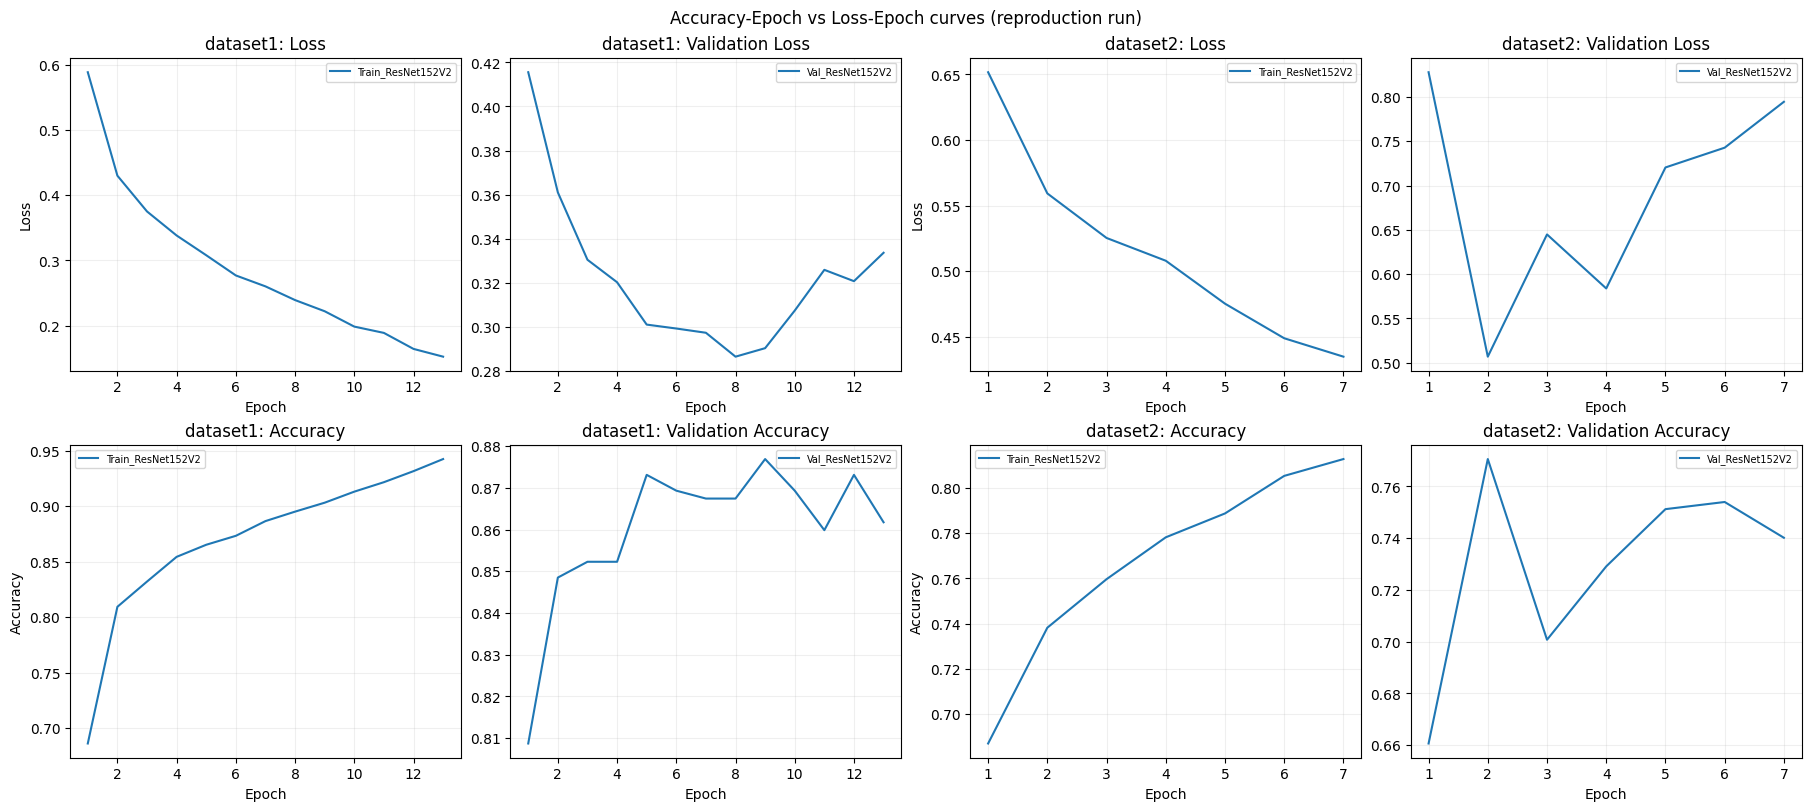

In [19]:
# 10A. Plot training and validation loss/accuracy curves for the four phase-1 architectures.

def load_history(dataset_key, stage, arch, member_id=1):
    p = ARTIFACT_ROOT / dataset_key / stage / f'{arch}_member{member_id}_history.json'
    if not p.exists():
        return None
    return json.loads(p.read_text())


arch_order = ['DenseNet201','ResNet152V2','MobileNetV2','InceptionResNetV2']

fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for col, ds in enumerate(['dataset1','dataset2']):
    pass

# The paper has four small plots per metric; this combined figure keeps the same information.
for ds_i, ds in enumerate(['dataset1','dataset2']):
    row_offset = 0 if ds == 'dataset1' else 1
    ax_loss = axes[0, ds_i*2]
    ax_val_loss = axes[0, ds_i*2+1]
    ax_acc = axes[1, ds_i*2]
    ax_val_acc = axes[1, ds_i*2+1]
    for arch in arch_order:
        hist = load_history(ds, 'phase1', arch, 1)
        if not hist:
            continue
        epochs = np.arange(1, len(hist['loss'])+1)
        ax_loss.plot(epochs, hist['loss'], label=f'Train_{arch}')
        ax_val_loss.plot(epochs, hist.get('val_loss', []), label=f'Val_{arch}')
        ax_acc.plot(epochs, hist['accuracy'], label=f'Train_{arch}')
        ax_val_acc.plot(epochs, hist.get('val_accuracy', []), label=f'Val_{arch}')
    ax_loss.set_title(f'{ds}: Loss')
    ax_val_loss.set_title(f'{ds}: Validation Loss')
    ax_acc.set_title(f'{ds}: Accuracy')
    ax_val_acc.set_title(f'{ds}: Validation Accuracy')
    for ax in [ax_loss, ax_val_loss, ax_acc, ax_val_acc]:
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.2)
    ax_loss.set_ylabel('Loss')
    ax_acc.set_ylabel('Accuracy')
    ax_loss.legend(fontsize=7)
    ax_val_loss.legend(fontsize=7)
    ax_acc.legend(fontsize=7)
    ax_val_acc.legend(fontsize=7)

plt.suptitle('Accuracy-Epoch vs Loss-Epoch curves (reproduction run)')
plt.show()

## 11. ROC curves for Phases 1, 2 and Final (paper Figs. 10–15)

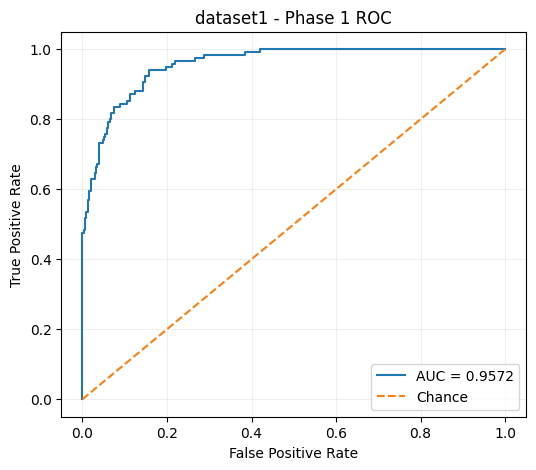

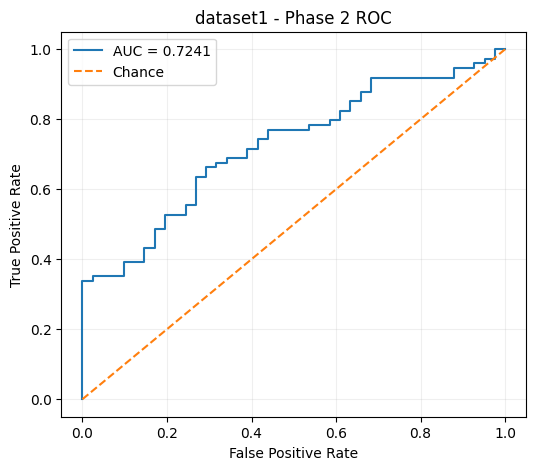

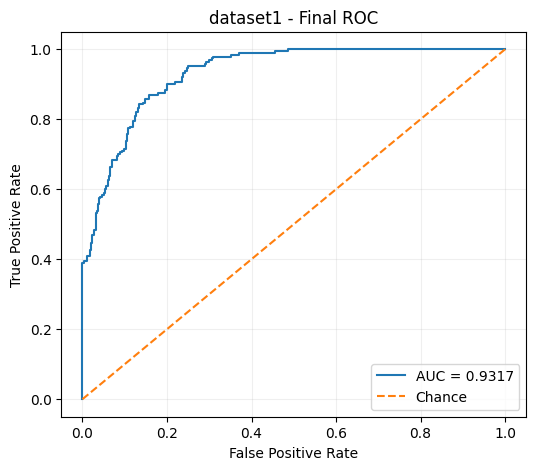

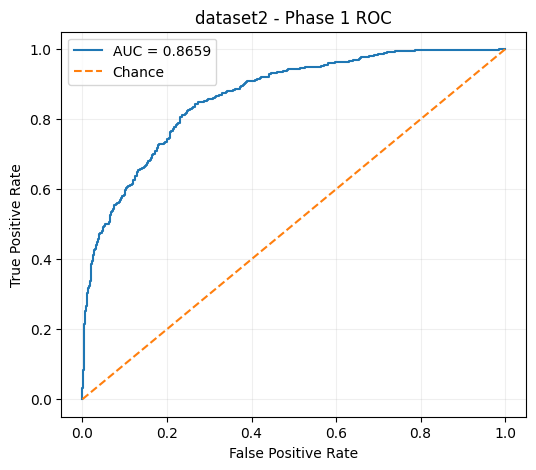

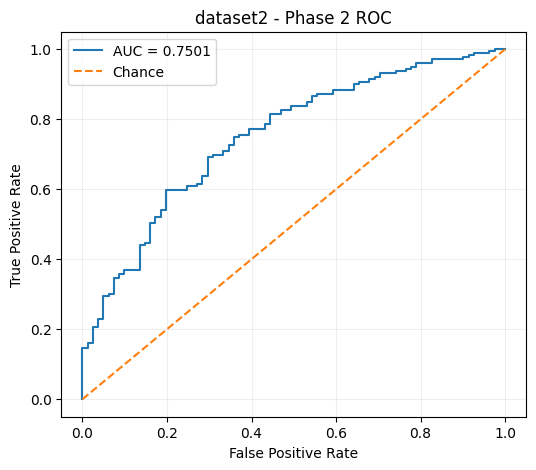

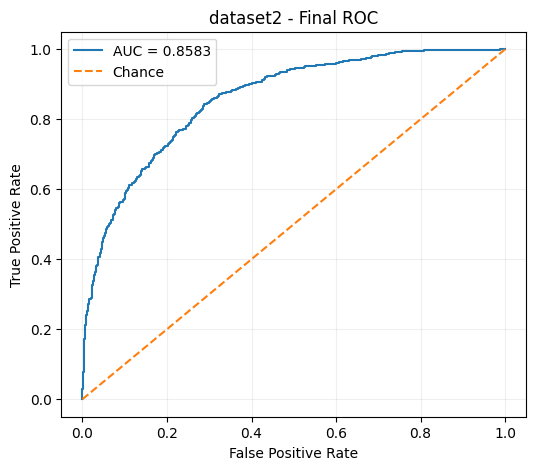

In [20]:
# 11A. Six ROC figures: dataset 1/2 x phase 1/2/final.

def plot_roc(title, y_true, score):
    fpr, tpr, _ = roc_curve(y_true, score)
    roc_auc = roc_auc_score(y_true, score)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
    plt.plot([0,1],[0,1], linestyle='--', label='Chance')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

for ds, spec in DATASET_SPECS.items():
    r = PIPELINE_RESULTS[ds]
    y = r['y_true']
    uq1 = r['phase1']['uq']; keep1 = ~r['phase1']['uncertain_mask']
    plot_roc(f'{ds} - Phase 1 ROC', y[keep1], uq1['score'][keep1])

    idx2 = r['phase1']['referred_idx']
    y2 = y[idx2]
    uq2 = r['phase2']['uq']; keep2 = ~r['phase2']['uncertain_mask']
    plot_roc(f'{ds} - Phase 2 ROC', y2[keep2], uq2['score'][keep2])

    plot_roc(f'{ds} - Final ROC', r['final']['y_true'], r['final']['score'])

## 12. Image samples (paper Figs. 6 and 7 style)

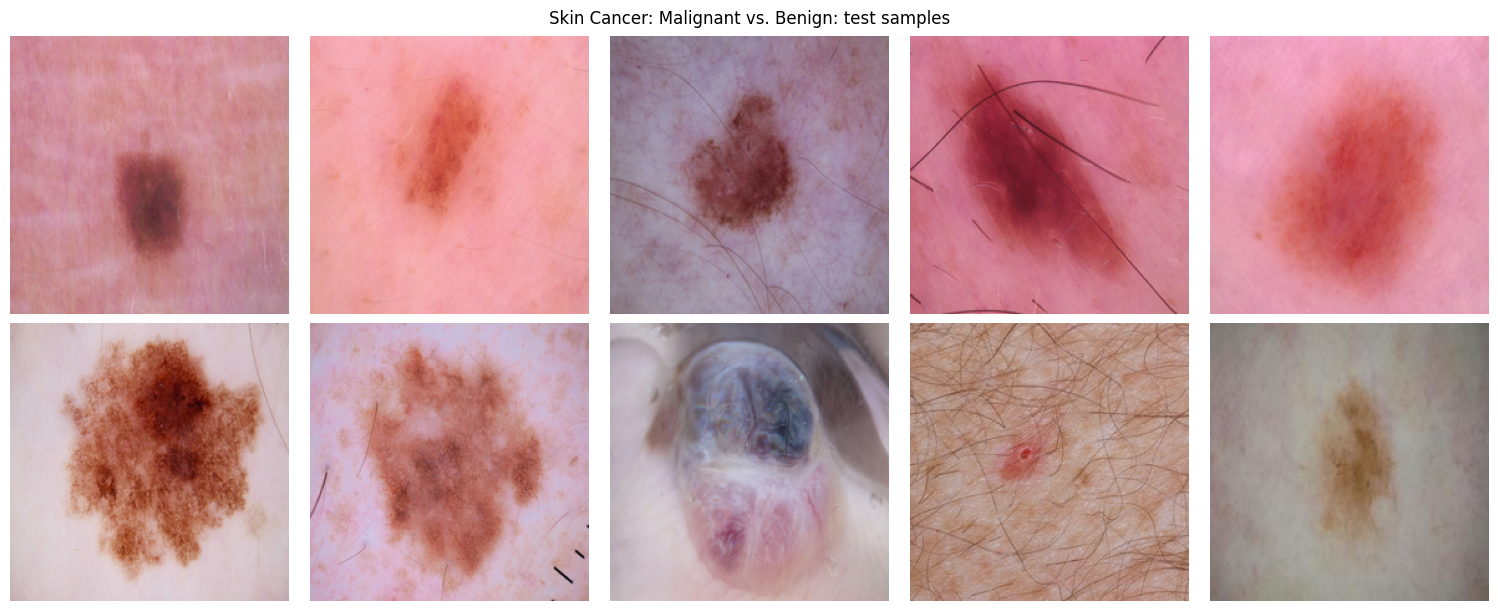

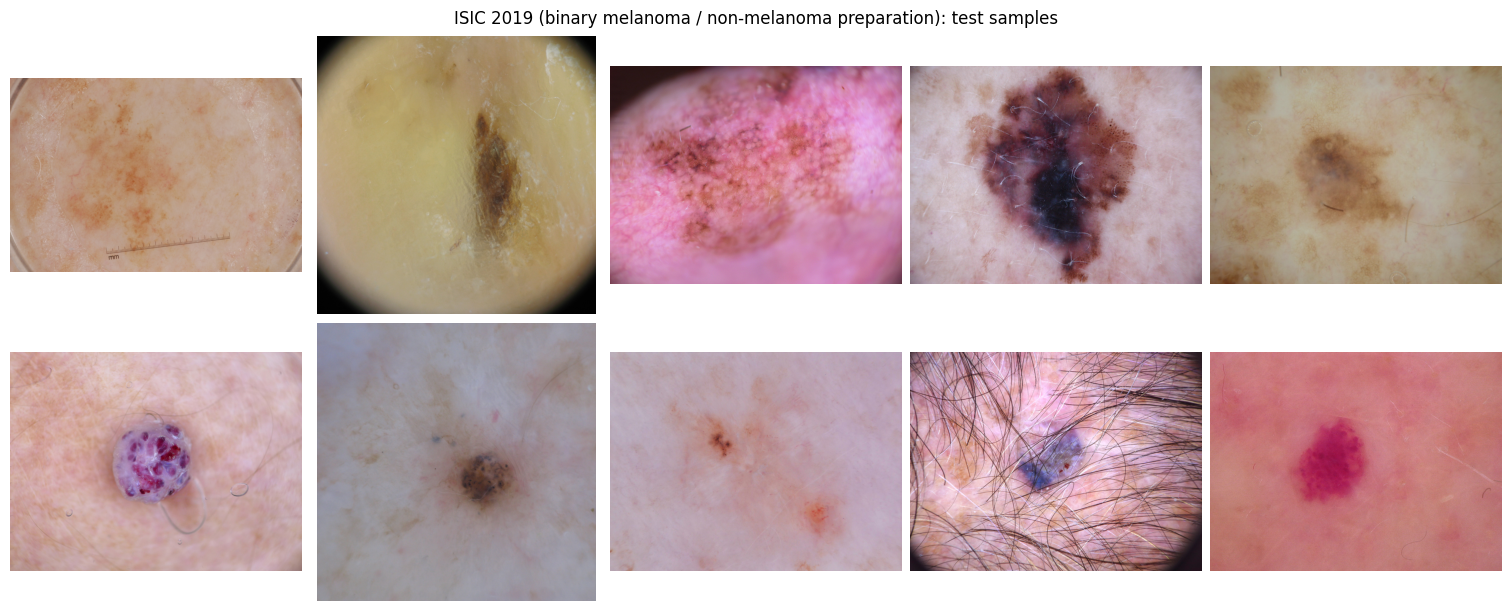

In [21]:
# 12A. Display five random examples from each class for each dataset.

def show_class_examples(dataset_key, n=5):
    df = manifests[dataset_key]['test']
    class_names = DATASET_SPECS[dataset_key]['class_names']
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6), constrained_layout=True)
    for row, label in enumerate([0,1]):
        subset = df[df.label == label]
        sample = subset.sample(n=min(n, len(subset)), random_state=SEED+row)
        for col, (_, rec) in enumerate(sample.reset_index(drop=True).iterrows()):
            img = plt.imread(rec['path'])
            axes[row, col].imshow(img)
            axes[row, col].axis('off')
        axes[row,0].set_ylabel(class_names[label], fontsize=12)
    plt.suptitle(f'{DATASET_SPECS[dataset_key]["name"]}: test samples')
    plt.show()

show_class_examples('dataset1')
show_class_examples('dataset2')

## 13. Grad-CAM visualizations (paper Figs. 8 and 9 style)

The paper does not state exactly which of the four backbones produced the displayed Grad-CAM examples. The notebook uses **ResNet152V2**, the first phase-1 backbone listed in the paper for both datasets, and selects five correctly classified and five incorrectly classified test images. Set `CAM_MODEL_ARCH` below to inspect another backbone.

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


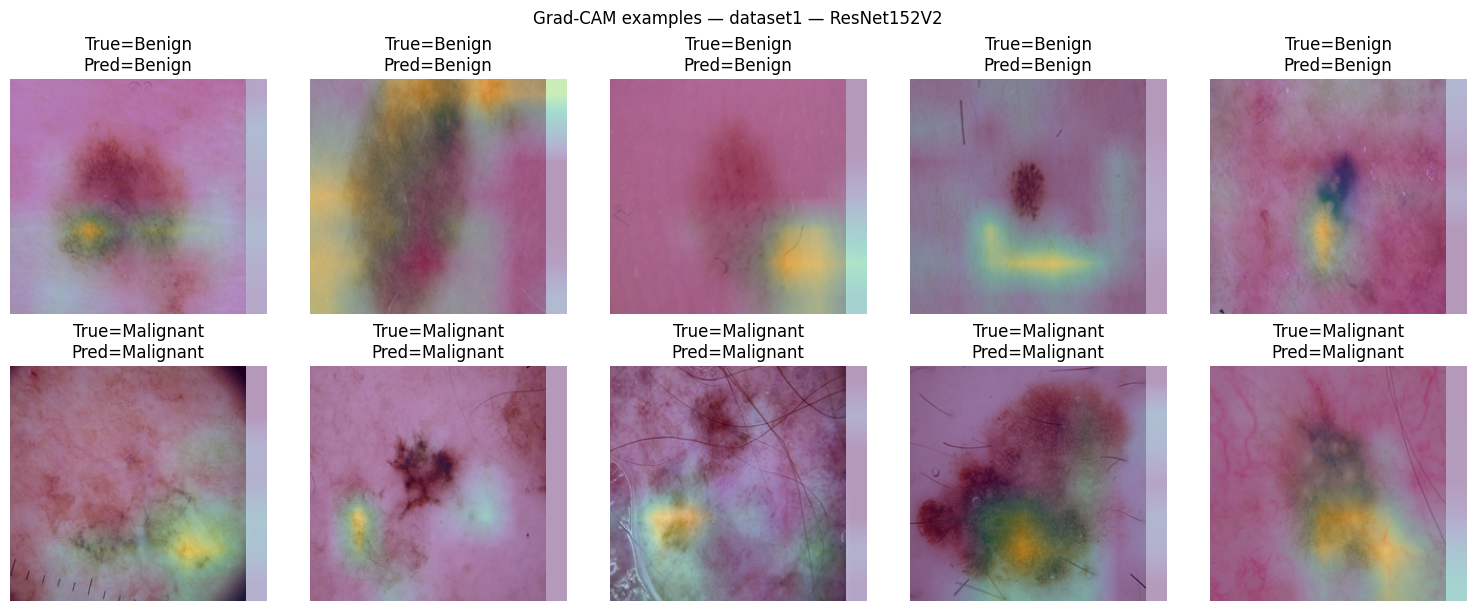

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 2 variables whereas the saved optimizer has 8 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


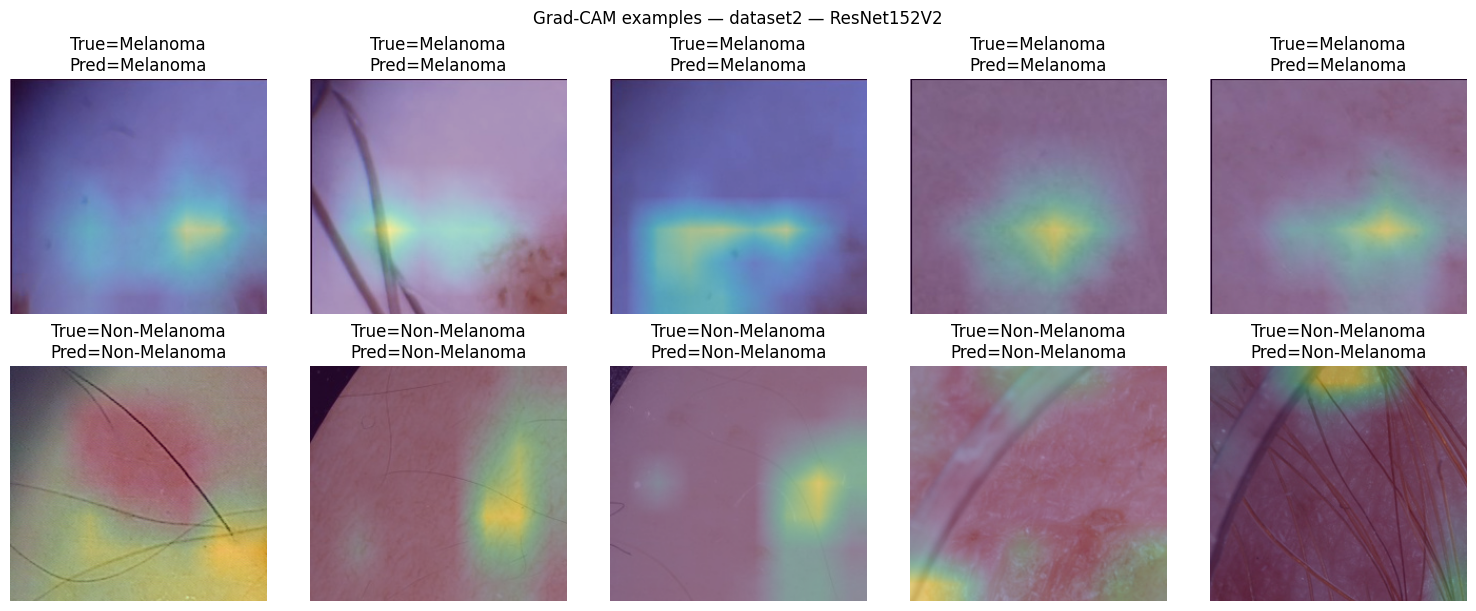

In [22]:
# 13A. Grad-CAM implementation for the custom TWDBDLClassifier.

CAM_MODEL_ARCH = 'ResNet152V2'


def last_conv_layer(base_model):
    conv_like = []
    for layer in base_model.layers:
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D, tf.keras.layers.SeparableConv2D)):
            conv_like.append(layer)
    if not conv_like:
        raise RuntimeError(f'No convolutional layer found in {base_model.name}')
    return conv_like[-1]


def make_cam(model, img_tensor, class_idx):
    target_layer = last_conv_layer(model.base)
    grad_model = tf.keras.Model(model.base.input, [target_layer.output, model.base.output])
    with tf.GradientTape() as tape:
        conv_out, base_out = grad_model(img_tensor, training=False)
        x = model.pool(base_out)
        x = model.fc0(x)
        x = model.fc1(x)
        x = model.dropout(x, training=False)
        probs = model.out(x)
        class_score = probs[:, class_idx]
    grads = tape.gradient(class_score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1,2))
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam, axis=(1,2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMAGE_SIZE)[..., 0]
    return cam.numpy()[0], probs.numpy()[0]


def plot_gradcam_examples(dataset_key, n_per_group=5):
    df = manifests[dataset_key]['test'].copy().reset_index(drop=True)
    y = df.label.to_numpy()
    model = load_member(dataset_key, 'phase1', CAM_MODEL_ARCH, 1)
    uq = PIPELINE_RESULTS[dataset_key]['phase1']['uq']
    correct = uq['pred'] == y
    chosen_correct = []
    chosen_wrong = []
    for label in [0,1]:
        idx = np.where((y==label) & correct)[0]
        chosen_correct.extend(idx[:n_per_group])
        idxw = np.where((y==label) & (~correct))[0]
        chosen_wrong.extend(idxw[:n_per_group])
    chosen = (chosen_correct + chosen_wrong)[:2*n_per_group]

    fig, axes = plt.subplots(2, n_per_group, figsize=(3*n_per_group, 6), constrained_layout=True)
    for j, idx in enumerate(chosen[:n_per_group]):
        rec = df.iloc[idx]
        raw = plt.imread(rec.path)
        img = tf.convert_to_tensor(np.array(raw)[None, ...], dtype=tf.float32)
        img = tf.image.resize(img, IMAGE_SIZE)
        img_pp = PREPROCESSORS[CAM_MODEL_ARCH](img)
        class_idx = int(uq['pred'][idx])
        cam, probs = make_cam(model, img_pp, class_idx)
        axes[0,j].imshow(raw)
        axes[0,j].imshow(cam, alpha=0.4)
        axes[0,j].set_title(f'True={DATASET_SPECS[dataset_key]["class_names"][int(y[idx])]}\nPred={DATASET_SPECS[dataset_key]["class_names"][class_idx]}')
        axes[0,j].axis('off')
    for j, idx in enumerate(chosen[n_per_group:2*n_per_group]):
        rec = df.iloc[idx]
        raw = plt.imread(rec.path)
        img = tf.convert_to_tensor(np.array(raw)[None, ...], dtype=tf.float32)
        img = tf.image.resize(img, IMAGE_SIZE)
        img_pp = PREPROCESSORS[CAM_MODEL_ARCH](img)
        class_idx = int(uq['pred'][idx])
        cam, probs = make_cam(model, img_pp, class_idx)
        axes[1,j].imshow(raw)
        axes[1,j].imshow(cam, alpha=0.4)
        axes[1,j].set_title(f'True={DATASET_SPECS[dataset_key]["class_names"][int(y[idx])]}\nPred={DATASET_SPECS[dataset_key]["class_names"][class_idx]}')
        axes[1,j].axis('off')
    axes[0,0].set_ylabel('Correct', fontsize=12)
    axes[1,0].set_ylabel('Incorrect', fontsize=12)
    plt.suptitle(f'Grad-CAM examples — {dataset_key} — {CAM_MODEL_ARCH}')
    plt.show()
    del model
    tf.keras.backend.clear_session()
    gc.collect()

plot_gradcam_examples('dataset1')
plot_gradcam_examples('dataset2')

## 14. Predictive distributions with entropy and STD (paper Figs. 16 and 17 style)

The paper illustrates two correctly classified and two misclassified cases for each dataset and shows the distribution of predicted probabilities together with uncertainty values. The sample identities are not reported, so the notebook selects cases automatically from the actual run.

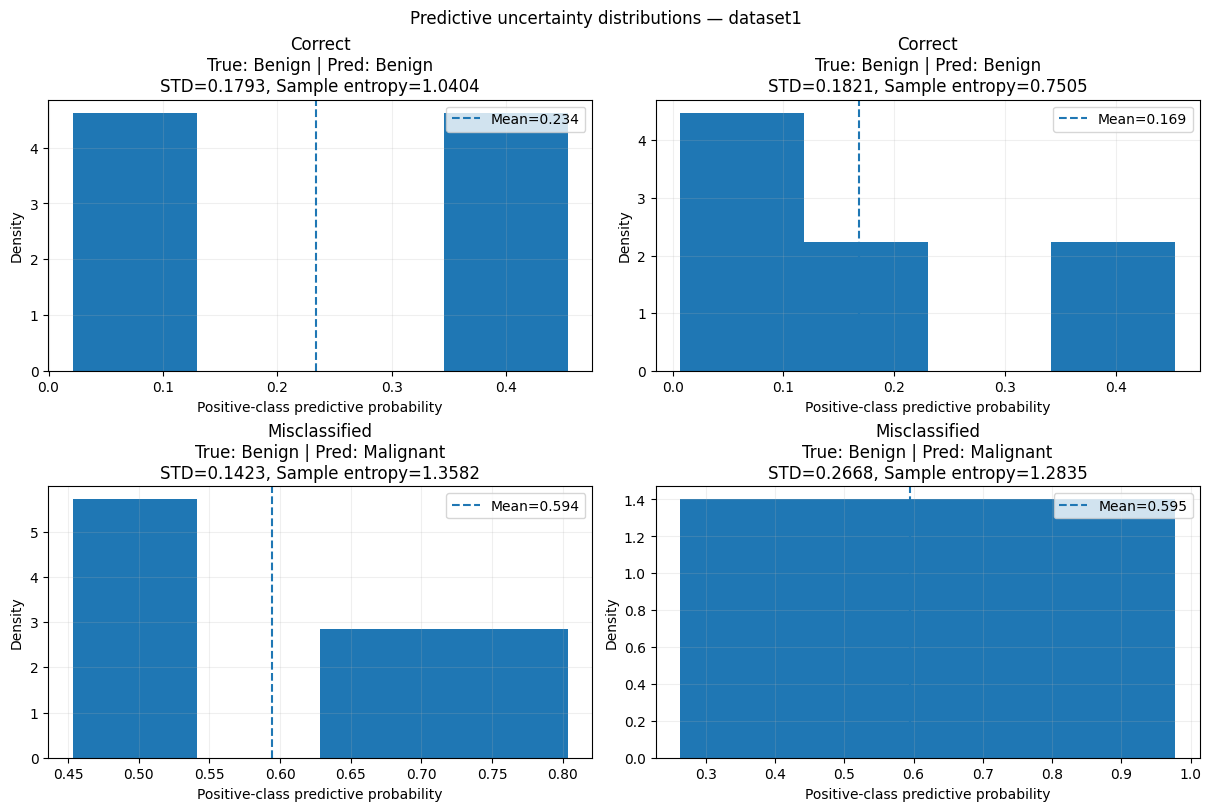

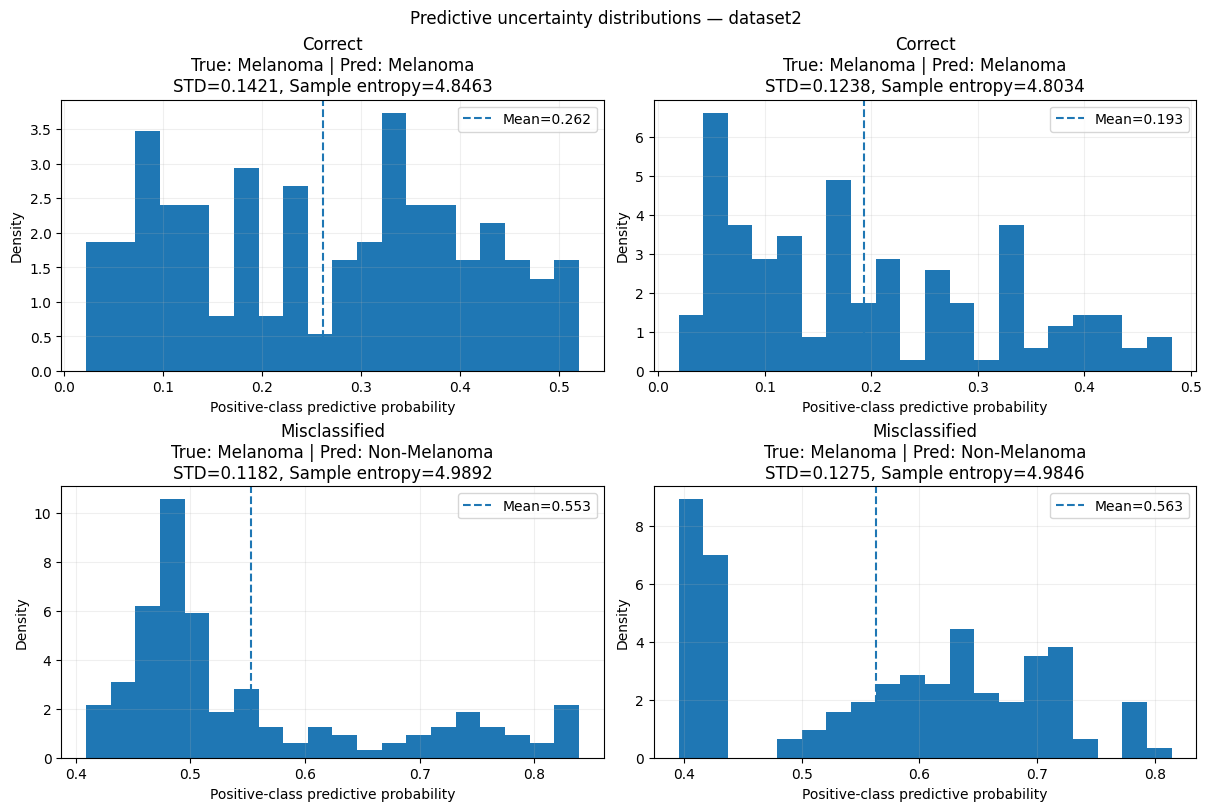

In [23]:
# 14A. Select two correct + two incorrect examples and show sampled predictive distributions.

def plot_predictive_distribution_examples(dataset_key):
    r = PIPELINE_RESULTS[dataset_key]
    uq = r['phase1']['uq']
    y = r['y_true']
    pred = uq['pred']
    correct = pred == y
    correct_idx = np.where(correct)[0][:2]
    wrong_idx = np.where(~correct)[0][:2]
    chosen = list(correct_idx) + list(wrong_idx)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    samples = uq['samples'][:, :, 1]
    for ax, idx in zip(axes.ravel(), chosen):
        ax.hist(samples[:, idx], bins=min(20, samples.shape[0]), density=True)
        ax.axvline(samples[:, idx].mean(), linestyle='--', label=f'Mean={samples[:,idx].mean():.3f}')
        status = 'Correct' if correct[idx] else 'Misclassified'
        cname = DATASET_SPECS[dataset_key]['class_names']
        ax.set_title(
            f'{status}\nTrue: {cname[int(y[idx])]} | Pred: {cname[int(pred[idx])]}'
            f'\nSTD={uq["std"][idx]:.4f}, Sample entropy={uq["entropy"][idx]:.4f}'
        )
        ax.set_xlabel('Positive-class predictive probability')
        ax.set_ylabel('Density')
        ax.legend()
        ax.grid(alpha=0.2)
    plt.suptitle(f'Predictive uncertainty distributions — {dataset_key}')
    plt.show()

plot_predictive_distribution_examples('dataset1')
plot_predictive_distribution_examples('dataset2')

## 15. Relationship between entropy, STD and misclassification

This section directly tests the paper's observation that misclassified samples tend to have larger uncertainty. It reports the mean entropy/STD for correct vs. incorrect samples, and visualizes the distributions.

,Dataset,Group,Count,Mean sample entropy,Mean STD,Mean conventional binary entropy
0,dataset1,Correct,569,1.006482,0.194074,0.491303
1,dataset1,Incorrect,91,1.310569,0.170232,0.637444
2,dataset2,Correct,1390,4.888827,0.121608,0.566040
3,dataset2,Incorrect,418,4.964034,0.115826,0.649668


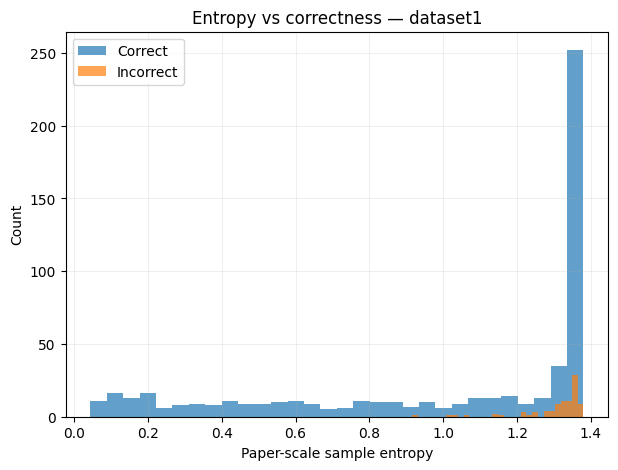

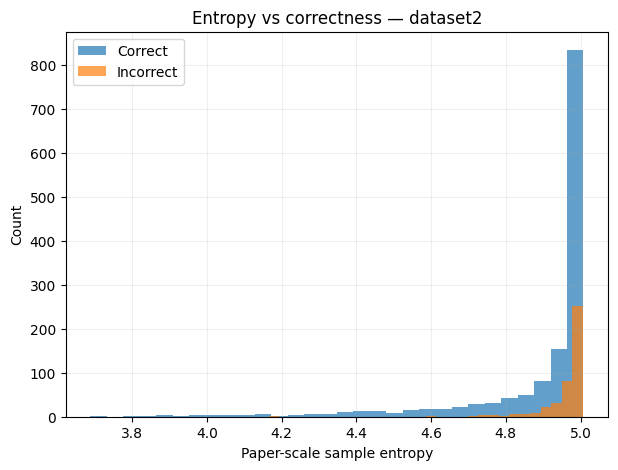

In [24]:
# 15A. Correct vs incorrect uncertainty analysis.
uncertainty_rows=[]
for ds in DATASET_SPECS:
    uq = PIPELINE_RESULTS[ds]['phase1']['uq']
    y = PIPELINE_RESULTS[ds]['y_true']
    pred = uq['pred']
    correct = pred == y
    for name, mask in [('Correct', correct), ('Incorrect', ~correct)]:
        uncertainty_rows.append({
            'Dataset': ds,
            'Group': name,
            'Count': int(mask.sum()),
            'Mean sample entropy': float(uq['entropy'][mask].mean()),
            'Mean STD': float(uq['std'][mask].mean()),
            'Mean conventional binary entropy': float(uq['conventional_entropy'][mask].mean()),
        })
uncertainty_df = pd.DataFrame(uncertainty_rows)
display(uncertainty_df)

for ds in DATASET_SPECS:
    uq = PIPELINE_RESULTS[ds]['phase1']['uq']
    y = PIPELINE_RESULTS[ds]['y_true']
    correct = uq['pred'] == y
    plt.figure(figsize=(7,5))
    plt.hist(uq['entropy'][correct], bins=30, alpha=0.7, label='Correct')
    plt.hist(uq['entropy'][~correct], bins=30, alpha=0.7, label='Incorrect')
    plt.xlabel('Paper-scale sample entropy')
    plt.ylabel('Count')
    plt.title(f'Entropy vs correctness — {ds}')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

## 16. Optional: reproduce the baseline comparisons in Tables 3–6

The main pipeline above is the paper's dynamic TWDBDL system. Re-running every baseline in Tables 3–6 is substantially more expensive because it requires additional trained MC/DE/EMC models for every backbone. The functions below are provided so the experiments are reproducible when compute/time permits.

The paper does not state the exact number of same-architecture members used for every EMC baseline, so `BASELINE_EMC_MEMBERS` is an explicit setting rather than a hidden assumption.

In [25]:
# 16A. Optional baseline-sweep configuration and utilities.
BASELINE_EMC_MEMBERS = 3
BASELINE_REFERRAL_RATES = [0.20, 0.50]


def train_baseline_members(dataset_key, arch, n_members):
    # Reuse stage-like directory so cached weights persist.
    train_df = manifests[dataset_key]['train']
    rows=[]
    for member_id in range(1, n_members+1):
        model, hist = train_member(dataset_key, 'baseline_sweeps', arch, member_id, train_df)
        rows.append((arch, member_id))
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    return rows


def baseline_uq(dataset_key, arch, method):
    method = method.upper()
    if method == 'MC':
        train_baseline_members(dataset_key, arch, 1)
        samples = collect_uq_samples(dataset_key, 'baseline_sweeps', [arch], 'MC', manifests[dataset_key]['test'])
    elif method == 'DE':
        train_baseline_members(dataset_key, arch, BASELINE_EMC_MEMBERS)
        samples = collect_uq_samples(dataset_key, 'baseline_sweeps', [arch]*BASELINE_EMC_MEMBERS, 'DE', manifests[dataset_key]['test'])
    elif method == 'EMC':
        train_baseline_members(dataset_key, arch, BASELINE_EMC_MEMBERS)
        samples = collect_uq_samples(dataset_key, 'baseline_sweeps', [arch]*BASELINE_EMC_MEMBERS, 'EMC', manifests[dataset_key]['test'])
    else:
        raise ValueError(method)
    return uq_from_samples(samples)


def run_referral_curve(uq, y_true, rates):
    rows=[]
    for rate in rates:
        n_unc = int(round(len(y_true)*rate))
        mask, threshold = top_n_uncertain_mask(uq['entropy'], n_unc)
        m = metrics_from_uq(uq, y_true, mask)
        rows.append({'Referral rate': rate, 'Threshold': threshold, 'Accuracy (%)': 100*m['accuracy'], 'F1-score (%)': 100*m['f1_weighted'], 'n_uncertain': n_unc})
    return pd.DataFrame(rows)


if RUN_BASELINE_SWEEPS:
    baseline_results = {}
    for ds in ['dataset1','dataset2']:
        for arch in ['DenseNet201','MobileNetV2','ResNet152V2','InceptionResNetV2']:
            for method in ['MC','EMC','DE']:
                print('\nRunning baseline:', ds, arch, method)
                uq = baseline_uq(ds, arch, method)
                m = metrics_from_uq(uq, manifests[ds]['test']['label'].to_numpy())
                baseline_results[(ds,arch,method)] = {'uq': uq, 'metrics': m}
    print('Baseline sweep complete.')
else:
    print('RUN_BASELINE_SWEEPS=False. Paper Tables 3–6 are shown above; set True to execute additional baselines.')

RUN_BASELINE_SWEEPS=False. Paper Tables 3–6 are shown above; set True to execute additional baselines.


## 17. Optional Bayesian Optimization

The paper states that Bayesian Optimization (BO) was used to tune the two FC-layer widths, activations, optimizer, learning rate and epochs, but it does not publish the exact search ranges, acquisition function settings, number of BO trials, data split or random seeds. Therefore, this notebook uses the reported Table 1/2 configurations as the **reproduction target**. The optional code below runs a clearly labeled approximate BO search using Keras Tuner if it is available.

In [26]:
# 17A. Optional approximate Bayesian optimization.
# This is deliberately disabled by default because each trial requires training a large frozen-backbone model.

if RUN_BO_SEARCH:
    try:
        import keras_tuner as kt
        print('keras-tuner version:', kt.__version__)

        # Example search-space only; it is NOT claimed to be the paper's unpublished search space.
        def build_bo_model(hp, dataset_key='dataset1', arch='DenseNet201'):
            base_hp = dict(PAPER_HPARAMS[dataset_key][arch])
            base_hp['Units0'] = hp.Int('Units0', min_value=128, max_value=512, step=64)
            base_hp['Units1'] = hp.Int('Units1', min_value=32, max_value=192, step=32)
            base_hp['Activation0'] = hp.Choice('Activation0', ['relu','sigmoid','swish'])
            base_hp['Activation1'] = hp.Choice('Activation1', ['relu','sigmoid','swish'])
            base_hp['Optimizer'] = hp.Choice('Optimizer', ['Adam','SGD','RMSprop'])
            base_hp['Learning rate'] = hp.Float('lr', 1e-4, 2e-2, sampling='log')
            model = TWDBDLClassifier(arch, base_hp, DROPOUT_RATE)
            _ = model(tf.zeros((1, IMAGE_SIZE[0], IMAGE_SIZE[1], 3)), training=False)
            model.compile(optimizer=make_optimizer(base_hp['Optimizer'], base_hp['Learning rate']), loss='categorical_crossentropy', metrics=['accuracy'])
            return model

        # Keep the example intentionally small. Increase max_trials/epochs only with adequate Kaggle GPU time.
        ds='dataset1'; arch='DenseNet201'
        tuner = kt.BayesianOptimization(
            lambda hp: build_bo_model(hp, ds, arch),
            objective='val_accuracy',
            max_trials=5,
            directory=str(ARTIFACT_ROOT / 'bo'),
            project_name=f'{ds}_{arch}_example',
            overwrite=False,
        )
        tr = manifests[ds]['train']
        trn, val = train_test_split(tr, test_size=VAL_SPLIT, stratify=tr.label, random_state=SEED)
        tuner.search(make_tf_dataset(trn, arch, True), validation_data=make_tf_dataset(val, arch, False), epochs=min(5, int(PAPER_HPARAMS[ds][arch]['Epoch'])))
        print('Approximate BO results:')
        display(tuner.results_summary(num_trials=5))
    except Exception as exc:
        print('Approximate BO could not run:', repr(exc))
else:
    print('RUN_BO_SEARCH=False. Exact paper-reported hyperparameters are used instead.')

RUN_BO_SEARCH=False. Exact paper-reported hyperparameters are used instead.


## 18. High-level TWDBDL flow

This flow mirrors the paper's three-way decision logic while keeping the dataset-specific model/UQ choices explicit.

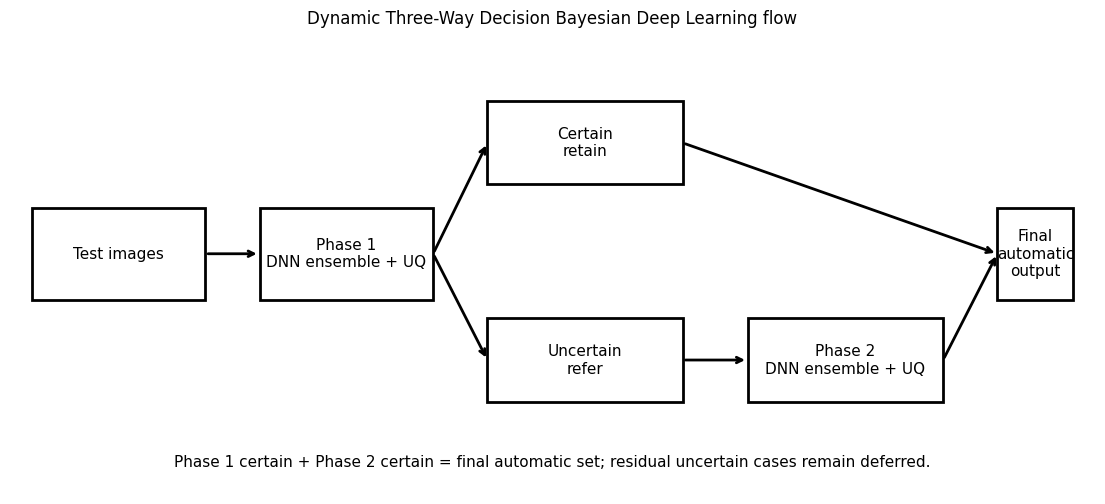

In [27]:
# 18A. Programmatic flow diagram.

fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('off')

boxes = [
    (0.02, 0.42, 0.16, 0.20, 'Test images'),
    (0.23, 0.42, 0.16, 0.20, 'Phase 1\nDNN ensemble + UQ'),
    (0.44, 0.67, 0.18, 0.18, 'Certain\nretain'),
    (0.44, 0.20, 0.18, 0.18, 'Uncertain\nrefer'),
    (0.68, 0.20, 0.18, 0.18, 'Phase 2\nDNN ensemble + UQ'),
    (0.91, 0.42, 0.07, 0.20, 'Final\nautomatic\noutput'),
]
for x,y,w,h,label in boxes:
    rect=plt.Rectangle((x,y),w,h,fill=False,linewidth=2)
    ax.add_patch(rect)
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=11)

# Arrows
arrows=[((0.18,0.52),(0.23,0.52)),((0.39,0.52),(0.44,0.76)),((0.39,0.52),(0.44,0.29)),((0.62,0.29),(0.68,0.29)),((0.86,0.29),(0.91,0.52)),((0.62,0.76),(0.91,0.52))]
for (x1,y1),(x2,y2) in arrows:
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops={'arrowstyle':'->','lw':2})

ax.text(0.50,0.06,'Phase 1 certain + Phase 2 certain = final automatic set; residual uncertain cases remain deferred.',ha='center',fontsize=11)
ax.set_title('Dynamic Three-Way Decision Bayesian Deep Learning flow')
plt.show()

## 19. Final comparison: paper-reported vs notebook reproduction

The most important distinction in this notebook is between the **reported 2021 paper values** and the **numbers produced by this Kaggle run**. They should not be treated as identical unless the same preprocessing, split, seeds, thresholds and other unpublished implementation choices are verified.

In [28]:
# 19A. Compare final reported values with this run.
comparison = PAPER_TABLE9.rename(columns={
    'Accuracy (%)':'Paper Accuracy (%)',
    'F1-score (%)':'Paper F1-score (%)',
    'AUC':'Paper AUC',
    'f1-0':'Paper F1-0 (%)',
    'f1-1':'Paper F1-1 (%)',
}).copy()
comparison['Dataset key'] = ['dataset1','dataset2']

repro = final_summary_df.rename(columns={
    'Accuracy (%)':'Repro Accuracy (%)',
    'F1-score (%)':'Repro F1-score (%)',
    'AUC':'Repro AUC',
    'F1-0 (%)':'Repro F1-0 (%)',
    'F1-1 (%)':'Repro F1-1 (%)',
}).copy()
repro['Dataset key'] = ['dataset1','dataset2']

comparison = comparison.merge(repro[['Dataset key','Repro F1-0 (%)','Repro F1-1 (%)','Repro Accuracy (%)','Repro F1-score (%)','Repro AUC','Deferred']], on='Dataset key')
display(comparison[['Dataset','Paper F1-0 (%)','Repro F1-0 (%)','Paper F1-1 (%)','Repro F1-1 (%)','Paper Accuracy (%)','Repro Accuracy (%)','Paper F1-score (%)','Repro F1-score (%)','Paper AUC','Repro AUC','Deferred']])

,Dataset,Paper F1-0 (%),Repro F1-0 (%),Paper F1-1 (%),Repro F1-1 (%),Paper Accuracy (%),Repro Accuracy (%),Paper F1-score (%),Repro F1-score (%),Paper AUC,Repro AUC,Deferred
0,First,92.0,88.633094,83.0,79.795396,88.95,85.451197,89.0,85.540713,0.92,0.931698,117
1,Second,91.0,77.620397,91.0,75.632326,90.96,76.668636,91.0,76.657480,0.97,0.858334,115


## 20. Reproducibility checklist and source limitations

1. **Dataset structure:** the loader uses the exact folder names supplied for this task and only reads JPG/JPEG files.
2. **Class mapping:** Dataset 1 = benign 0 / malignant 1; Dataset 2 = melanoma 0 / non-melanoma 1, matching the paper.
3. **Backbones:** the four paper architectures are implemented with frozen ImageNet weights.
4. **Classification head:** two FC layers + dropout 0.5 + 2-class softmax.
5. **UQ:** MC=50 stochastic passes; DE averages independent deterministic models; EMC averages stochastic passes from multiple ensemble members.
6. **Entropy:** the notebook reports both the conventional binary predictive entropy and the paper-scale sampled entropy used for uncertainty ranking.
7. **TWD thresholds:** the exact numeric entropy thresholds are not printed in the paper; the notebook calibrates the number of referrals to the paper's reported counts.
8. **Bayesian Optimization:** the paper's exact BO search-space/trial details are not given; reported Table 1/2 hyperparameters are therefore used as the main target.
9. **Network morphism:** the paper mentions network morphisms, but does not provide a concrete morphism procedure. The notebook preserves the reported network head configurations rather than inventing an undocumented transformation.
10. **Grad-CAM:** exact figure sample IDs/backbone are not supplied; the notebook selects representative examples automatically and exposes the backbone choice.
11. **Validation/preprocessing:** the notebook uses ImageNet preprocessing and a 20% stratified validation split; both are configurable because the paper does not document these details sufficiently for exact reconstruction.

### Expected paper reference values

- Dataset 1 final: **88.95% accuracy, 89.00% F1, 0.92 AUC**.
- Dataset 2 final: **90.96% accuracy, 91.00% F1, 0.97 AUC**.

These are quoted as the paper's reported results, not as a guarantee of the current run's output.

## 21. Run-time tips for Kaggle

The full model suite is large, especially InceptionResNetV2, ResNet152V2 and the 50-pass EMC stages. The notebook caches each trained member under `/kaggle/working/twdbdl_artifacts`, so a disconnected/restarted analysis cell can reuse already trained weights when the session still contains the working directory.

For a smoke test, set `MAX_TRAIN_SAMPLES`, `MAX_TEST_SAMPLES` and `EPOCHS_OVERRIDE` near the top, run the notebook once, then restore them to `None` for the full experiment.

For the paper-style result, keep `MC_PASSES=50`, use the exact reported hyperparameters, and run the main TWDBDL three-phase pipeline. Optional baseline sweeps and approximate BO are disabled by default because they add substantial compute.